# explanation about my analyse

-git , jupyter, docker env , conda , 
- trimm et starsolo sur cluster 
- metadata : serait bien de rajouter colums 
- convert to Anndata
single cell en local (3000 cellules seulement)



- fonctionalisation
  - graph qualité 
  - graph boxplot variation entre replicas
  - summarise
  - thresold
  
  - shiny app 
  - shiny in jupyter



- deux methodes choisi pour le filtrage :   
  - kuchina (60.000 cells) + rm doublets
  - Val thresold (3000 cells)
  - other knew-point... pas testé 


-Val : 
    - best features sur l'ensemble de matrices 
    - rm doublets 
    - best ncount / sur l'ensemble de matrices 
    - conserve only mRNA 
  
  => test post => voit un replica tech pas bon (pipetage maybe)
 
Question : DOL dans les 6 conditions : DO , Stress 

- considerer batch effet : rep tech, rep bio => creation variable rep 
rep bio peut ne pas etre consideré comme batch 


Integration globale :
alors batch est replica tech 


SCtransform, anchor
scvi sur python  




- voir solène comment choisi 3000 cells



tirage aleatoire de 30 cellules par Rep_bio_tech donc tres faible; possibilité de certains biais lié a tailles des lots faibles ( tirage possible de cellules exprime faiblement et autre fortement ), cellules non stressés ont plus grand ecart type , 
attention certain barcode sont peut etre mieux aussi , hibride mieux , quantité de cellules par condition pas égale...

je vais avoir besoin de detailler mes focntions 

si stress trop fort , bloque totalement la transcrisp, ou sinon pas de cellule viable pour les conditions stressés 

est ce que c'est pertinenat de considerer comme cellules uniques ( mRNA mobile) => holo

besoin de retirer les doublet a un moment avant 
test de la methode log 
faire grph 

voir si il y a de la variabilité alpha , beta , gamma 

# Import libraries and seurat object  

In [4]:
library(Seurat)
library(ggplot2)
library(dplyr)
library(sctransform)
library(tibble)
library(purrr)
library(patchwork)
library(glmGamPoi)
library(rlang)
library(ggrepel)
library(readxl)


In [2]:
setwd("/workspaces/microsplit_DOL")


# Add metadata to the Seurat object

In [5]:
# Read the Seurat object
# input_file <- "data/processed/Seurat_object/SeuratObject_All.rds"
input_file <- "data/big_data/RDS_files/SeuratObject_All.rds"
seurat_object <- readRDS(input_file)

# Read barcode QC file for round 1
barcode_qc_file_rd1 <- "data/processed_data/metadata_DOL_Exp1/barqc/barcode_rd1_barqc.csv"
barcode_qc_rd1 <- read.csv(barcode_qc_file_rd1, stringsAsFactors = FALSE)

# Print diagnostic information about barcode QC file
cat("\nBarcode QC file information for round 1:\n")
cat("Number of barcodes in QC file:", nrow(barcode_qc_rd1), "\n")
cat("First few rows of barcode QC file:\n")
print(head(barcode_qc_rd1))

# Match barcodes and add Well_loc_rd1
matching_wells_rd1 <- match(seurat_object$barcode.rd1, barcode_qc_rd1$Barcode)
seurat_object$Well_loc_rd1 <- barcode_qc_rd1$Well[matching_wells_rd1]

# Print diagnostic information about the matching
cat("\nWell location matching information for round 1:\n")
cat("Number of matched cells:", sum(!is.na(matching_wells_rd1)), "\n")
cat("Number of unmatched cells:", sum(is.na(matching_wells_rd1)), "\n")
cat("First few Well_loc_rd1 values:\n")
print(head(seurat_object$Well_loc_rd1))

# Read barcode QC file for round 2
barcode_qc_file <- "data/processed_data/metadata_DOL_Exp1/barqc/barcode_rd2_barqc.csv"
barcode_qc_rd2 <- read.csv(barcode_qc_file, stringsAsFactors = FALSE)

# Print diagnostic information about barcode QC file
cat("\nBarcode QC file information for round 2:\n")
cat("Number of barcodes in QC file:", nrow(barcode_qc_rd2), "\n")
cat("First few rows of barcode QC file:\n")
print(head(barcode_qc_rd2))

# Match barcodes and add Well_loc_rd2
matching_wells_rd2 <- match(seurat_object$barcode.rd2, barcode_qc_rd2$Barcode)
seurat_object$Well_loc_rd2 <- barcode_qc_rd2$Well[matching_wells_rd2]

# Print diagnostic information about the matching
cat("\nWell location matching information for round 2:\n")
cat("Number of matched cells:", sum(!is.na(matching_wells_rd2)), "\n")
cat("Number of unmatched cells:", sum(is.na(matching_wells_rd2)), "\n")
cat("First few Well_loc_rd2 values:\n")
print(head(seurat_object$Well_loc_rd2))

# Read barcode QC file for round 3
barcode_qc_file_rd3 <- "data/processed_data/metadata_DOL_Exp1/barqc/barcode_rd3_barqc.csv"
barcode_qc_rd3 <- read.csv(barcode_qc_file_rd3, stringsAsFactors = FALSE)

# Print diagnostic information about barcode QC file
cat("\nBarcode QC file information for round 3:\n")
cat("Number of barcodes in QC file:", nrow(barcode_qc_rd3), "\n")
cat("First few rows of barcode QC file:\n")
print(head(barcode_qc_rd3))

# Match barcodes and add Well_loc_rd3
matching_wells_rd3 <- match(seurat_object$barcode.rd3, barcode_qc_rd3$Barcode)
seurat_object$Well_loc_rd3 <- barcode_qc_rd3$Well[matching_wells_rd3]

# Print diagnostic information about the matching
cat("\nWell location matching information for round 3:\n")
cat("Number of matched cells:", sum(!is.na(matching_wells_rd3)), "\n")
cat("Number of unmatched cells:", sum(is.na(matching_wells_rd3)), "\n")
cat("First few Well_loc_rd3 values:\n")
print(head(seurat_object$Well_loc_rd3))

# Add metadata from Excel file
metadata_file <- "data/processed_data/metadata_DOL_Exp1/metadata_DOL_Exp1_complete.xlsx"
metadata <- read_excel(metadata_file)

# Print column names of metadata
cat("\nColumns in metadata file:\n")
print(colnames(metadata))

# Print some diagnostic information
cat("\nDiagnostic information:\n")
cat("Number of cells in Seurat object:", length(seurat_object$barcode.rd1), "\n")
cat("Number of rows in metadata:", nrow(metadata), "\n")

# Print some example values to compare
cat("\nFirst few barcode.rd1 values:\n")
head(seurat_object$barcode.rd1)
cat("\nFirst few Extracted_Sequence_rd1 values:\n")
head(metadata$Extracted_Sequence_rd1)

# Match metadata with Seurat object based on barcode.rd1 and Extracted_Sequence.rd1
matching_cells <- match(seurat_object$barcode.rd1, metadata$Extracted_Sequence_rd1)

# Count number of matches
cat("\nNumber of matched cells:", sum(!is.na(matching_cells)), "\n")
cat("Number of unmatched cells:", sum(is.na(matching_cells)), "\n")

# Add metadata columns to Seurat object
seurat_object$Sample_ID <- metadata$Sample_ID[matching_cells]
seurat_object$Culture_medium <- metadata$Culture_medium[matching_cells]
seurat_object$Rep_bio <- metadata$Rep_bio[matching_cells]
seurat_object$Rep_tech <- metadata$Rep_tech[matching_cells]
seurat_object$OD_timepoint <- metadata$OD_timepoint[matching_cells]
seurat_object$OD_theoric <- metadata$OD_theoric[matching_cells]
seurat_object$OD_measured <- metadata$OD_measured[matching_cells]
seurat_object$Condition <- metadata$Condition[matching_cells]

# Add gene annotation from TSV file
annotation_file <- "data/raw_data/genome_annotation/other/extracted_features.tsv"
gene_annotation <- read.delim(annotation_file,
  sep = "\t",
  header = TRUE,
  stringsAsFactors = FALSE,
  quote = "", # Désactive l'interprétation des guillemets
  na.strings = c("NA", "")
) # Gère les valeurs manquantes

# Create a mapping between locus_tag and gene names
# Replace underscores with hyphens in locus_tag to match Seurat object format
gene_annotation$feature_id <- gsub("_", "-", gene_annotation$locus_tag)

# Create a comprehensive mapping that includes both locus tags and symbols
# First, create a mapping for locus tags
locus_mapping <- match(rownames(seurat_object), gene_annotation$feature_id)

# Then, create a mapping for symbols (only for non-empty symbols)
symbol_annotation <- gene_annotation[!is.na(gene_annotation$symbol) & gene_annotation$symbol != "", ]
symbol_mapping <- match(rownames(seurat_object), symbol_annotation$symbol)

# Combine the mappings, prioritizing locus tag matches
matching_genes <- locus_mapping
# For genes that weren't matched by locus tag, use symbol match if available
unmatched_genes <- is.na(matching_genes)
if (any(unmatched_genes)) {
  symbol_matches <- symbol_mapping[unmatched_genes]
  # Convert symbol matches back to original annotation indices
  symbol_indices <- symbol_annotation$feature_id[symbol_matches]
  symbol_to_original <- match(symbol_indices, gene_annotation$feature_id)
  matching_genes[unmatched_genes] <- symbol_to_original
}

# Create a data frame with all annotations
feature_metadata <- data.frame(
  seq_type = gene_annotation$seq_type[matching_genes],
  feature = gene_annotation$feature[matching_genes],
  class = gene_annotation$class[matching_genes],
  product_accession = gene_annotation$product_accession[matching_genes],
  name = gene_annotation$name[matching_genes],
  symbol = gene_annotation$symbol[matching_genes],
  locus_tag = gene_annotation$locus_tag[matching_genes],
  row.names = rownames(seurat_object)
)

# Add feature metadata to Seurat object
seurat_object[["RNA"]] <- AddMetaData(
  object = seurat_object[["RNA"]],
  metadata = feature_metadata
)

# Print some diagnostic information about the gene matching
cat("\nGene annotation information:\n")
cat("Number of features in Seurat object:", nrow(seurat_object), "\n")
cat("Number of genes in annotation file:", nrow(gene_annotation), "\n")
cat("Number of matched genes:", sum(!is.na(matching_genes)), "\n")
cat("Number of unmatched genes:", sum(is.na(matching_genes)), "\n")

# Check specific genes like katG
katg_index <- which(rownames(seurat_object) == "katG")
if (length(katg_index) > 0) {
  cat("\nkatG gene information:\n")
  cat("katG found at index:", katg_index, "\n")
  cat("katG symbol in annotation:", gene_annotation$symbol[matching_genes[katg_index]], "\n")
  cat("katG locus tag in annotation:", gene_annotation$locus_tag[matching_genes[katg_index]], "\n")
  cat("katG name in annotation:", gene_annotation$name[matching_genes[katg_index]], "\n")
}

# Check other known genes with symbols
known_symbols <- c("recC", "recB", "recD", "mmsB", "leuA", "fur", "recN", "grpE", "dnaK", "dnaJ")
for (symbol in known_symbols) {
  symbol_index <- which(rownames(seurat_object) == symbol)
  if (length(symbol_index) > 0) {
    cat("\n", symbol, " gene information:\n")
    cat(symbol, " found at index:", symbol_index, "\n")
    cat(symbol, " symbol in annotation:", gene_annotation$symbol[matching_genes[symbol_index]], "\n")
    cat(symbol, " locus tag in annotation:", gene_annotation$locus_tag[matching_genes[symbol_index]], "\n")
  }
}

# Print unique values in each annotation column
cat("\nUnique values in feature column:\n")
print(unique(seurat_object[["RNA"]][[]]$feature))
cat("\nUnique values in seq_type column:\n")
print(unique(seurat_object[["RNA"]][[]]$seq_type))
cat("\nUnique values in class column:\n")
print(unique(seurat_object[["RNA"]][[]]$class))

# Count number of each feature type
cat("\nCount of each feature type:\n")
print(table(seurat_object[["RNA"]][[]]$feature))

# Save updated Seurat object with metadata in a new file
# output_file <- "data/processed/Seurat_object/SeuratObject_All_Metadata.rds"
output_file <- "data/big_data/RDS_files/SeuratObject_All_Metadata.rds"
saveRDS(seurat_object, file = output_file)

# Verify if the file was successfully created
if (file.exists(output_file)) {
  # Get file information
  file_info <- file.info(output_file)

  # Display file information
  cat("✓ Seurat object with metadata successfully saved:", output_file, "\n")
  cat("File size:", round(file_info$size / 1024 / 1024, 2), "MB\n")
  cat("Creation date:", format(file_info$mtime, "%Y-%m-%d %H:%M:%S"), "\n")

  # Display Seurat object dimensions
  cat("\nSeurat object with metadata information:\n")
  cat("Number of cells:", ncol(seurat_object), "\n")
  cat("Number of genes:", nrow(seurat_object), "\n")
} else {
  cat("❌ Error: The file was not created.")
}

# Print the duplicated features
if (any(duplicated(rownames(seurat_object)))) {
  cat("\nDuplicated features found:\n")
  duplicated_features <- rownames(seurat_object)[duplicated(rownames(seurat_object))]
  print(duplicated_features)
} else {
  cat("\nNo duplicated features found.\n")
}



str(seurat_object)



print(colnames(seurat_object[["RNA"]][[]]))



# Print summary of the Seurat object structure
print(str(seurat_object))

assay_obj <- seurat_object[["RNA"]]
print(assay_obj)

# Print the first few rows of gene metadata
head(assay_obj@meta.data)

# Accéder à l'assay par défaut de l'objet Seurat
head(seurat_object@assays$RNA@meta.data)
# list colnames of the assay
colnames(seurat_object@assays$RNA@meta.data)

# list columns of the metadata
colnames(seurat_object@meta.data)



Barcode QC file information for round 1:
Number of barcodes in QC file: 90 
First few rows of barcode QC file:
  WellPosition     Name  Barcode
1           A1 Barcode1 ACTCGTAA
2           A2 Barcode1 AAACGATA
3           A3 Barcode1 TTACCTCG
4           A4 Barcode1 GCCTGCAA
5           A5 Barcode1 TGGTATAC
6           A6 Barcode1 CGTTCGAG

Well location matching information for round 1:
Number of matched cells: 820800 
Number of unmatched cells: 0 
First few Well_loc_rd1 values:
AAACATCG_AAACATCG_AAACGATA AACAACCA_AAACATCG_AAACGATA 
                      "A2"                       "A2" 
AACCGAGA_AAACATCG_AAACGATA AACGCTTA_AAACATCG_AAACGATA 
                      "A2"                       "A2" 
AACGTGAT_AAACATCG_AAACGATA AACTCACC_AAACATCG_AAACGATA 
                      "A2"                       "A2" 

Barcode QC file information for round 2:
Number of barcodes in QC file: 96 
First few rows of barcode QC file:
  WellPosition     Name  Barcode
1           A1 Barcode2 AACGTGAT
2     

AAACATCG_AAACATCG_AAACGATA AACAACCA_AAACATCG_AAACGATA 
                "AAACGATA"                 "AAACGATA" 
AACCGAGA_AAACATCG_AAACGATA AACGCTTA_AAACATCG_AAACGATA 
                "AAACGATA"                 "AAACGATA" 
AACGTGAT_AAACATCG_AAACGATA AACTCACC_AAACATCG_AAACGATA 
                "AAACGATA"                 "AAACGATA"


First few Extracted_Sequence_rd1 values:


[1] "ACTCGTAA" "TGGCGCGC" "TGCTTGGG" "GCCGTGTA" "ATCCGCGA" "AAACGATA"


Number of matched cells: 820800 
Number of unmatched cells: 0 

Gene annotation information:
Number of features in Seurat object: 6248 
Number of genes in annotation file: 6249 
Number of matched genes: 6116 
Number of unmatched genes: 132 

katG gene information:
katG found at index: 39 
katG symbol in annotation: katG 
katG locus tag in annotation: QLH64_00195 
katG name in annotation: catalase/peroxidase HPI 

 recC  gene information:
recC  found at index: 6 
recC  symbol in annotation: recC 
recC  locus tag in annotation: QLH64_00030 

 recB  gene information:
recB  found at index: 7 
recB  symbol in annotation: recB 
recB  locus tag in annotation: QLH64_00035 

 recD  gene information:
recD  found at index: 8 
recD  symbol in annotation: recD 
recD  locus tag in annotation: QLH64_00040 

 mmsB  gene information:
mmsB  found at index: 17 
mmsB  symbol in annotation: mmsB 
mmsB  locus tag in annotation: QLH64_00085 

 leuA  gene information:
leuA  found at index: 77 
leuA  symbol i

,seq_type,feature,class,product_accession,name,symbol,locus_tag
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,chromosome,rRNA,NA,NA,16S ribosomal RNA,NA,QLH64_00005
2,chromosome,tRNA,NA,NA,tRNA-Ile,NA,QLH64_00010
3,chromosome,tRNA,NA,NA,tRNA-Ala,NA,QLH64_00015
4,chromosome,rRNA,NA,NA,23S ribosomal RNA,NA,QLH64_00020
5,chromosome,rRNA,NA,NA,5S ribosomal RNA,rrf,QLH64_00025
6,chromosome,CDS,with_protein,WHS54405.1,exodeoxyribonuclease V subunit gamma,recC,QLH64_00030


,seq_type,feature,class,product_accession,name,symbol,locus_tag
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,chromosome,rRNA,NA,NA,16S ribosomal RNA,NA,QLH64_00005
2,chromosome,tRNA,NA,NA,tRNA-Ile,NA,QLH64_00010
3,chromosome,tRNA,NA,NA,tRNA-Ala,NA,QLH64_00015
4,chromosome,rRNA,NA,NA,23S ribosomal RNA,NA,QLH64_00020
5,chromosome,rRNA,NA,NA,5S ribosomal RNA,rrf,QLH64_00025
6,chromosome,CDS,with_protein,WHS54405.1,exodeoxyribonuclease V subunit gamma,recC,QLH64_00030


[1] "seq_type"          "feature"           "class"            
[4] "product_accession" "name"              "symbol"           
[7] "locus_tag"

[1] "nCount_RNA"     "nFeature_RNA"   "barcode.rd1"    "barcode.rd2"   
 [5] "barcode.rd3"    "Well_loc_rd1"   "Well_loc_rd2"   "Well_loc_rd3"  
 [9] "Sample_ID"      "Culture_medium" "Rep_bio"        "Rep_tech"      
[13] "OD_timepoint"   "OD_theoric"     "OD_measured"    "Condition"

# Check the NA in features 

In [6]:
# Load the Seurat object
seurat_obj <- readRDS("data/big_data/RDS_files/SeuratObject_All_Metadata.rds")


## Check general aspect of the object

In [6]:
cat("Available assays:\n")
print(Assays(seurat_obj))

cat("\nAvailable layers:\n")
print(Layers(seurat_obj))

# choose the assay to work with
GetAssay(seurat_obj, assay = "RNA")


# str of the Seurat object
# str(seurat_obj)


Available assays:
[1] "RNA"

Available layers:


[1] "counts"


Assay (v5) data with 6248 features for 820800 cells
First 10 features:
 QLH64-00005, QLH64-00010, QLH64-00015, QLH64-00020, rrf, recC, recB,
recD, QLH64-00045, QLH64-00050 
Layers:
 counts 

In [7]:
# Display first rows of metadata
cat("\nMetadata overview:\n")
head(seurat_obj@meta.data)

# Display available columns
cat("\nAvailable columns in metadata:\n")
colnames(seurat_obj@meta.data)



Metadata overview:


,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>
AAACATCG_AAACATCG_AAACGATA,49,44,AAACGATA,AAACATCG,AAACATCG,A2,A2,A2,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress
AACAACCA_AAACATCG_AAACGATA,8,14,AAACGATA,AAACATCG,AACAACCA,A2,A2,B1,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress
AACCGAGA_AAACATCG_AAACGATA,33,34,AAACGATA,AAACATCG,AACCGAGA,A2,A2,B2,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress
AACGCTTA_AAACATCG_AAACGATA,119,89,AAACGATA,AAACATCG,AACGCTTA,A2,A2,B3,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress
AACGTGAT_AAACATCG_AAACGATA,2,10,AAACGATA,AAACATCG,AACGTGAT,A2,A2,A1,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress
AACTCACC_AAACATCG_AAACGATA,1,5,AAACGATA,AAACATCG,AACTCACC,A2,A2,F9,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress



Available columns in metadata:


[1] "nCount_RNA"     "nFeature_RNA"   "barcode.rd1"    "barcode.rd2"   
 [5] "barcode.rd3"    "Well_loc_rd1"   "Well_loc_rd2"   "Well_loc_rd3"  
 [9] "Sample_ID"      "Culture_medium" "Rep_bio"        "Rep_tech"      
[13] "OD_timepoint"   "OD_theoric"     "OD_measured"    "Condition"

## Create new colums  (maybe need to be implemented in metadata)

In [8]:
# create a new variable in the metadata call
seurat_obj$Condition_OD_timepoint <- paste(
    seurat_obj$Condition,
    seurat_obj$OD_timepoint,
    sep = "_"
)
seurat_obj$Rep <- paste(
    seurat_obj$Rep_bio,
    seurat_obj$Rep_tech,
    sep = "_"
)

seurat_obj$Condition_OD_timepoint_Rep_bio <- paste(
    seurat_obj$Condition_OD_timepoint,
    seurat_obj$Rep_bio,
    sep = "_"
)
# Display available columns
cat("\nAvailable columns in metadata:\n")
colnames(seurat_obj@meta.data)



Available columns in metadata:


[1] "nCount_RNA"                     "nFeature_RNA"                  
 [3] "barcode.rd1"                    "barcode.rd2"                   
 [5] "barcode.rd3"                    "Well_loc_rd1"                  
 [7] "Well_loc_rd2"                   "Well_loc_rd3"                  
 [9] "Sample_ID"                      "Culture_medium"                
[11] "Rep_bio"                        "Rep_tech"                      
[13] "OD_timepoint"                   "OD_theoric"                    
[15] "OD_measured"                    "Condition"                     
[17] "Condition_OD_timepoint"         "Rep"                           
[19] "Condition_OD_timepoint_Rep_bio"

In [9]:
# see the genes info layer metadata
colnames(GetAssay(seurat_obj, assay = "RNA")@meta.data)
head(GetAssay(seurat_obj, assay = "RNA")@meta.data, 100)


[1] "seq_type"          "feature"           "class"            
[4] "product_accession" "name"              "symbol"           
[7] "locus_tag"

,seq_type,feature,class,product_accession,name,symbol,locus_tag
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,chromosome,rRNA,NA,NA,16S ribosomal RNA,NA,QLH64_00005
2,chromosome,tRNA,NA,NA,tRNA-Ile,NA,QLH64_00010
3,chromosome,tRNA,NA,NA,tRNA-Ala,NA,QLH64_00015
4,chromosome,rRNA,NA,NA,23S ribosomal RNA,NA,QLH64_00020
5,chromosome,rRNA,NA,NA,5S ribosomal RNA,rrf,QLH64_00025
6,chromosome,CDS,with_protein,WHS54405.1,exodeoxyribonuclease V subunit gamma,recC,QLH64_00030
7,chromosome,CDS,with_protein,WHS54406.1,exodeoxyribonuclease V subunit beta,recB,QLH64_00035
8,chromosome,CDS,with_protein,WHS54407.1,exodeoxyribonuclease V subunit alpha,recD,QLH64_00040
9,chromosome,CDS,with_protein,WHS54408.1,YfiR family protein,NA,QLH64_00045


Revoir car beaucoup de NA , ligne vides , ou aussi la colonne "symbol" qui est vide

In [10]:
# View the feature type distribution for CDS-filtered object
feature_metadata <- seurat_obj[["RNA"]][[]]

feature_summary <- feature_metadata %>%
    count(feature) %>%
    mutate(percentage = round(n / sum(n) * 100, 2)) %>%
    arrange(desc(n))

View(feature_summary)


feature,n,percentage
<chr>,<int>,<dbl>
CDS,6036,96.61
NA,132,2.11
tRNA,65,1.04
rRNA,11,0.18
ncRNA,3,0.05
tmRNA,1,0.02


In [8]:
# Save RDS file with the new colums
dir.create("jupyter/correct/ScObjects", recursive = TRUE, showWarnings = FALSE)
saveRDS(seurat_obj, "jupyter/correct/ScObjects/SeuratObject_All_Metadata.rds")


# Convert to Anndata object for use with Scanpy and SCVI

In [50]:
# Fonction to convert

# Required packages
library(Seurat)
library(scCustomize)
library(anndata)
library(reticulate)

# Configure reticulate to use conda
message("Configuring reticulate to use conda...")

# Use the conda environment
use_condaenv("env_reticulate", required = TRUE)


# Verify Python configuration
message("Verifying Python configuration...")
message("Python version:", py_version())
message("Python path:", py_config()$python)

# check if scanpy, pandas and anndata are installed and available and print their versions
packages <- py_list_packages()
cat("scanpy installed:", "scanpy" %in% packages$package, "\n")
cat("pandas installed:", "pandas" %in% packages$package, "\n")
cat("anndata installed:", "anndata" %in% packages$package, "\n")




# check if anndata is available
reticulate::py_module_available(module = "anndata")


Configuring reticulate to use conda...

Verifying Python configuration...

Python version:3.9

Python path:/opt/conda/envs/env_reticulate/bin/python



scanpy installed: TRUE 
pandas installed: TRUE 
anndata installed: TRUE 


[1] TRUE

In [51]:
convert_seurat_to_anndata <- function(input_file, assay_name = "RNA", main_layer = "counts") {
  # Load required packages
  if (!requireNamespace("Seurat", quietly = TRUE)) stop("The 'Seurat' package is required.")
  if (!requireNamespace("scCustomize", quietly = TRUE)) stop("The 'scCustomize' package is required.")
  if (!requireNamespace("anndata", quietly = TRUE)) stop("The 'anndata' package is required.")
  if (!requireNamespace("reticulate", quietly = TRUE)) stop("The 'reticulate' package is required.")

  message("Reading RDS file: ", input_file)

  # Check if file exists
  if (!file.exists(input_file)) stop("File not found: ", input_file)

  # Load the Seurat object
  seurat_object <- readRDS(input_file)

  # Check that the requested assay exists
  if (!assay_name %in% names(seurat_object@assays)) {
    stop("Assay '", assay_name, "' not found in the Seurat object.")
  }

  # Set default assay
  Seurat::DefaultAssay(seurat_object) <- assay_name

  # Extract metadata
  seurat_meta <- seurat_object@meta.data

  # Define output file path
  output_dir <- dirname(input_file)
  output_name <- tools::file_path_sans_ext(basename(input_file))
  output_file <- file.path(output_dir, paste0(output_name, ".h5ad"))

  message("Converting to AnnData...")
  message("Output file: ", output_file)

  # Convert using scCustomize
  scCustomize::as.anndata(
    x = seurat_object,
    file_path = output_dir,
    file_name = paste0(output_name, ".h5ad"),
    main_layer = main_layer,
    other_layers = NULL,
    obs_names = colnames(seurat_object),
    var_names = rownames(seurat_object[[assay_name]]),
    obs = seurat_meta
  )

  # Check if file was created
  if (!file.exists(output_file)) stop("Failed to write the .h5ad file.")

  message("Successfully converted to .h5ad: ", output_file)

  # Verify with initial read
  message("Verifying output .h5ad file...")
  adata <- anndata::read_h5ad(output_file)

  # Add gene annotation with Python
  message("Adding feature metadata using Python...")

  reticulate::py_run_string(sprintf("
import pandas as pd
import anndata as ad
import numpy as np

# Load annotation TSV file
annotation_file = 'data/raw_data/genome_annotation/other/extracted_features.tsv'
gene_annotation = pd.read_csv(annotation_file, sep='\\t')

# Load the AnnData object
adata = ad.read_h5ad('%s')

# Prepare a mapping of locus_tag to row indices
locus_tag_map = dict(zip(gene_annotation['locus_tag'], gene_annotation.index))

# Initialize a DataFrame to hold metadata
var_metadata = pd.DataFrame(index=adata.var_names)

# Add all columns from gene annotation, initializing with None
for col in gene_annotation.columns:
    var_metadata[col] = None

# Fill the metadata
for gene_id in adata.var_names:
    locus_tag = gene_id.replace('gene-', '').replace('-', '_')
    if locus_tag in locus_tag_map:
        annotation_idx = locus_tag_map[locus_tag]
        for col in gene_annotation.columns:
            value = gene_annotation.loc[annotation_idx, col]
            var_metadata.at[gene_id, col] = '' if pd.isna(value) else str(value)

# Reorder metadata to match var index
var_metadata = var_metadata.reindex(adata.var_names)

# Add metadata columns to AnnData var
for col in var_metadata.columns:
    adata.var[col] = var_metadata[col]

# Save updated object
adata.write_h5ad('%s')

# Report summary
print('\\n Feature metadata columns added:')
print(var_metadata.columns.tolist())
print('\\n Number of features with annotations:', sum(var_metadata.notna().any(axis=1)))
", output_file, output_file))

  # Reload updated AnnData
  message("Reading updated AnnData object...")
  adata <- anndata::read_h5ad(output_file)

  message("Columns present in AnnData's `var` (feature metadata):")
  print(colnames(adata$var))

  message("The AnnData object is now ready in the variable `adata`.")
  message("You can continue your analysis in Python using Scanpy or other tools.")

  return(adata)
}


In [52]:
adata <- convert_seurat_to_anndata(
  input_file = "jupyter/correct/ScObjects/SeuratObject_All_Metadata.rds"
)


Reading RDS file: jupyter/correct/ScObjects/SeuratObject_All_Metadata.rds

Converting to AnnData...

Output file: jupyter/correct/ScObjects/SeuratObject_All_Metadata.h5ad

* Checking Seurat object validity
* Extracting Data from RNA assay to transfer to anndata.
* Creating anndata object.
* Writing anndata file:
  "/workspaces/microsplit_DOL/jupyter/correct/ScObjects/SeuratObject_All_Metadata.h5ad"
Successfully converted to .h5ad: jupyter/correct/ScObjects/SeuratObject_All_Metadata.h5ad

Verifying output .h5ad file...

Adding feature metadata using Python...

Reading updated AnnData object...

Columns present in AnnData's `var` (feature metadata):



[1] "names"             "seq_type"          "feature"          
[4] "class"             "product_accession" "name"             
[7] "symbol"            "locus_tag"        


The AnnData object is now ready in the variable `adata`.

You can continue your analysis in Python using Scanpy or other tools.



# First Quality Check and graphs

## Fonction to generate graphs quality

In [11]:
generate_qc_plots <- function(
    seurat_obj,
    subtitle,
    group.by = "Condition_OD_timepoint",
    split.by = NULL,
    show.points = FALSE) {
    # Vérification du paramètre obligatoire
    if (missing(subtitle) || is.null(subtitle) || subtitle == "") {
        stop("Le paramètre 'subtitle' est obligatoire.")
    }

    # Taille des points selon show.points
    pt.size.val <- ifelse(show.points, 1, 0)

    # p1 : Nombre de gènes par cellule
    p1 <- VlnPlot(seurat_obj,
        features = "nFeature_RNA",
        ncol = 1,
        pt.size = pt.size.val,
        group.by = group.by,
        raster = TRUE,
        layer = "counts"
    ) +
        labs(
            title = "Number of genes per cell",
            subtitle = subtitle,
            x = group.by,
            y = "Number of genes (nFeature_RNA)"
        ) +
        scale_y_continuous(limits = c(0, NA))

    # p2 : Nombre de counts par cellule
    p2 <- VlnPlot(seurat_obj,
        features = "nCount_RNA",
        ncol = 1,
        pt.size = pt.size.val,
        group.by = group.by,
        raster = TRUE,
        layer = "counts"
    ) +
        labs(
            title = "Number of counts per cell",
            subtitle = subtitle,
            x = group.by,
            y = "Number of counts (nCount_RNA)"
        ) +
        scale_y_continuous(limits = c(0, NA))

    # p3 : Scatter plot avec split facultatif
    p3 <- FeatureScatter(seurat_obj,
        feature1 = "nCount_RNA",
        feature2 = "nFeature_RNA",
        group.by = group.by,
        raster = TRUE,
        split.by = split.by
    )

    # p4 : RidgePlot avec annotation du nombre de cellules
    cell_counts_df <- seurat_obj@meta.data %>%
        group_by(across(all_of(group.by))) %>%
        summarise(n = n(), .groups = "drop")

    cell_counts_label <- paste0(cell_counts_df[[group.by]], " (n=", cell_counts_df$n, ")", collapse = "\n")

    p4 <- RidgePlot(seurat_obj,
        features = "nCount_RNA",
        group.by = group.by,
        log = TRUE
    ) +
        theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
        labs(
            title = paste("Distribution of UMIs per cell across conditions\n", cell_counts_label),
            subtitle = subtitle,
            x = "Number of UMIs per cell (log scale)",
            y = "Density"
        )

    # Combine p1 and p2
    combined_p1_p2 <- p1 / p2

    # Retour
    return(list(
        p1 = p1,
        p2 = p2,
        combined_p1_p2 = combined_p1_p2,
        scatter_p3 = p3,
        ridge_p4 = p4
    ))
}


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Warning message:
"Removed 11600 rows containing non-finite outside the scale range
(`stat_ydensity()`)."
Warning message:
"Removed 11600 rows containing non-finite outside the scale range
(`stat_ydensity()`)."


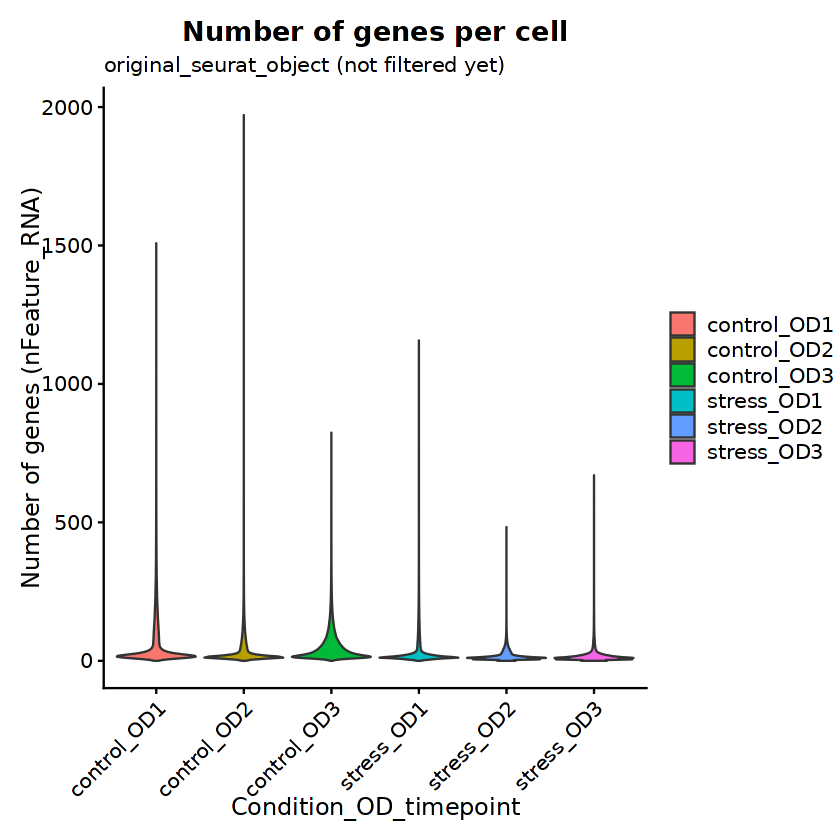

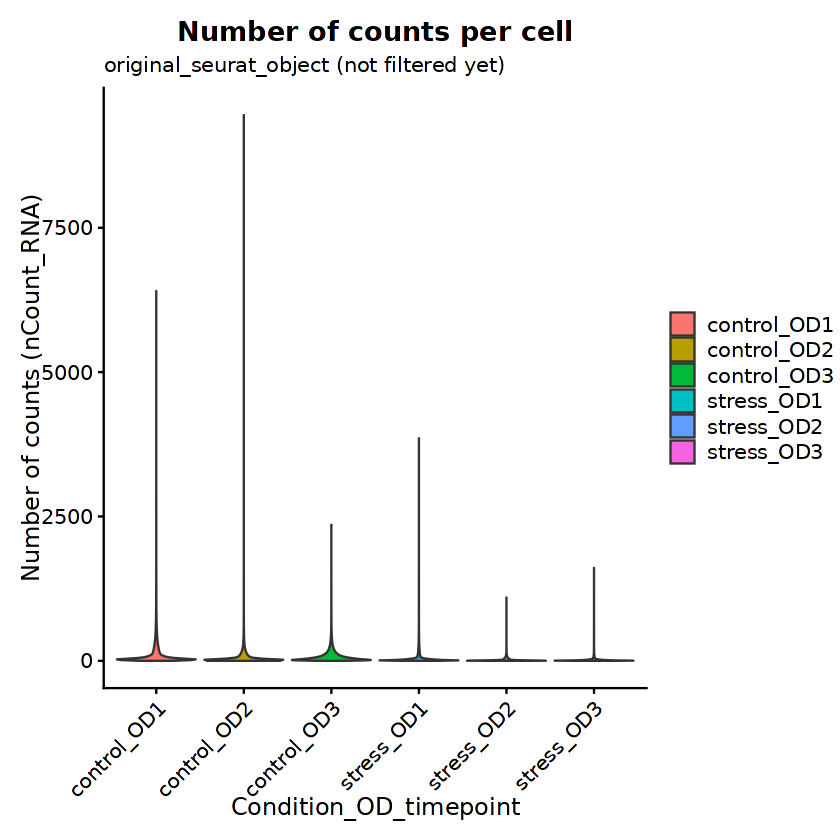

Picking joint bandwidth of 0.0463



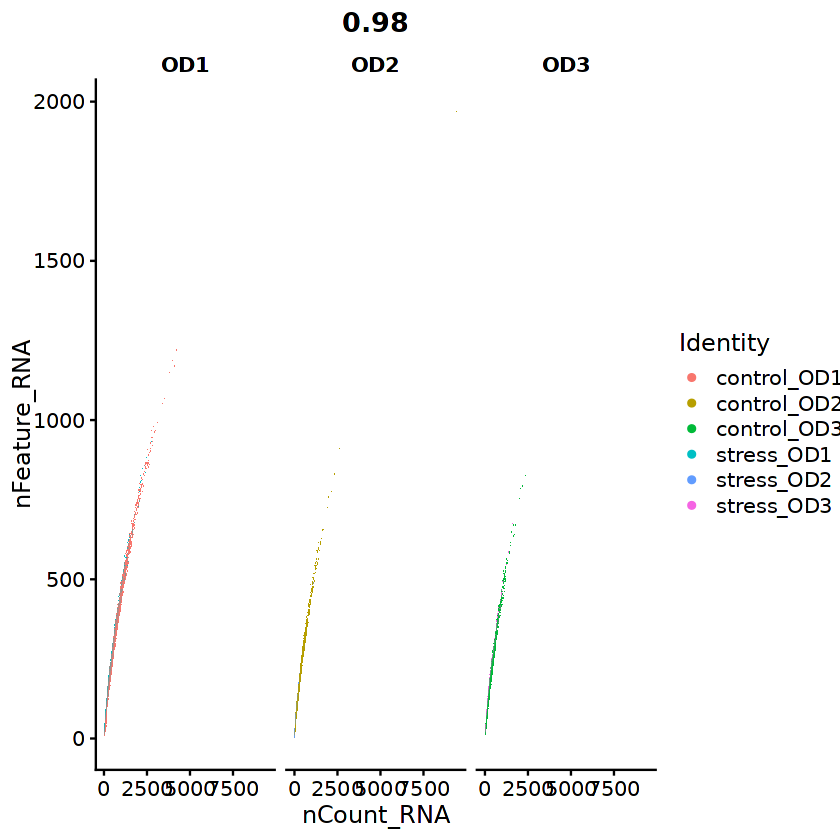

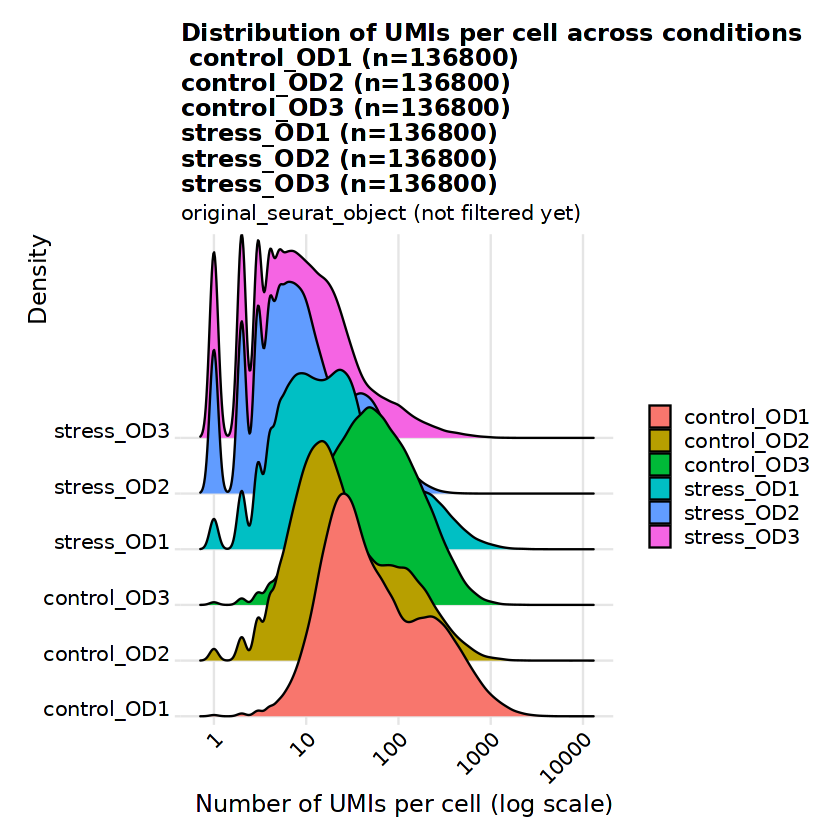

In [12]:
plots_without_point <- generate_qc_plots(
    seurat_obj = seurat_obj,
    subtitle = "original_seurat_object (not filtered yet)",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = FALSE
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Warning message:
"Removed 11600 rows containing non-finite outside the scale range
(`stat_ydensity()`)."
Warning message:
"Removed 11600 rows containing missing values or values outside the scale range
(`geom_point()`)."
Warning message:
"Removed 11600 rows containing non-finite outside the scale range
(`stat_ydensity()`)."
Warning message:
"Removed 11600 rows containing missing values or values outside the scale range
(`geom_point()`)."


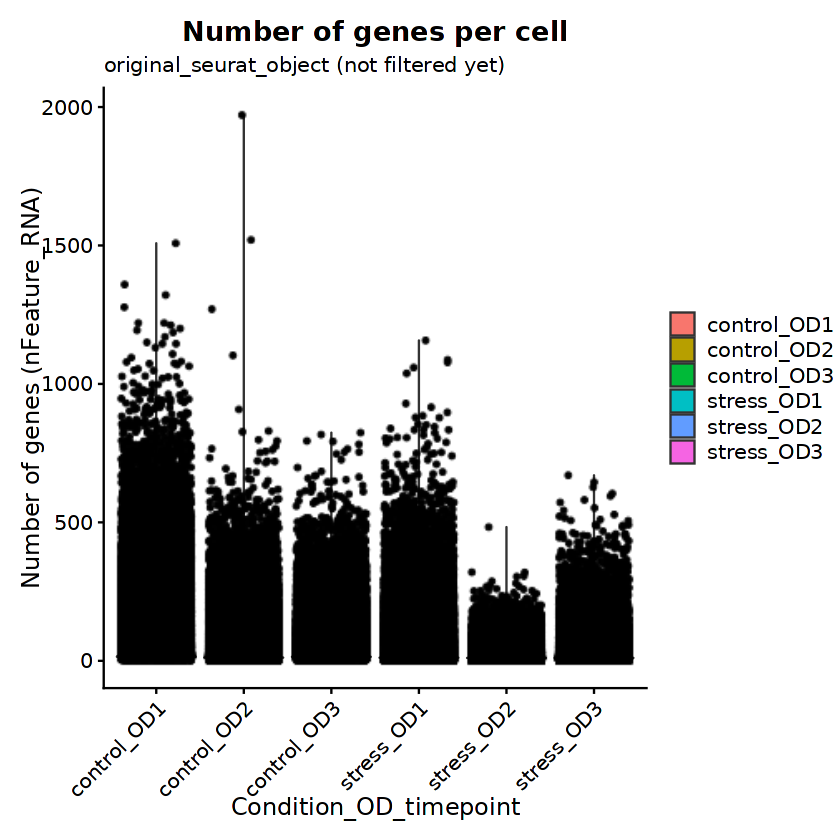

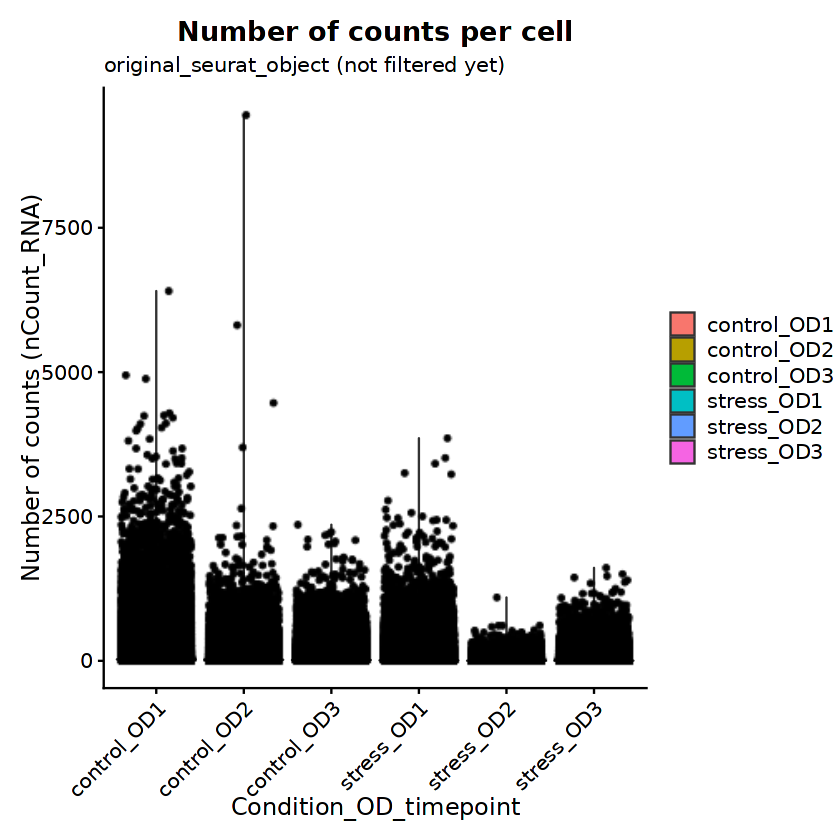

Picking joint bandwidth of 0.0463



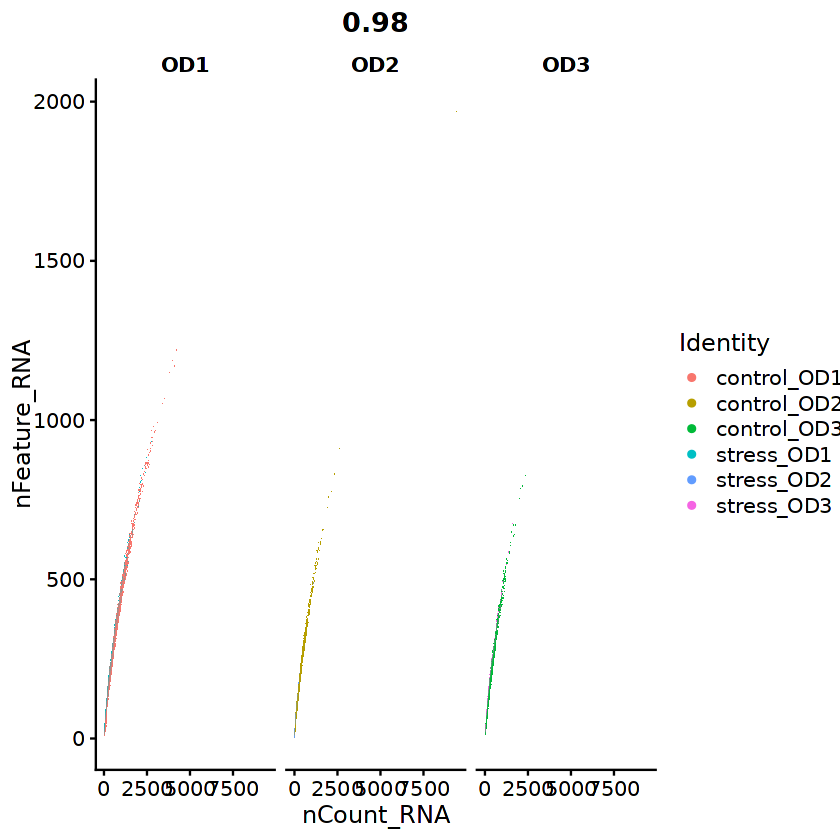

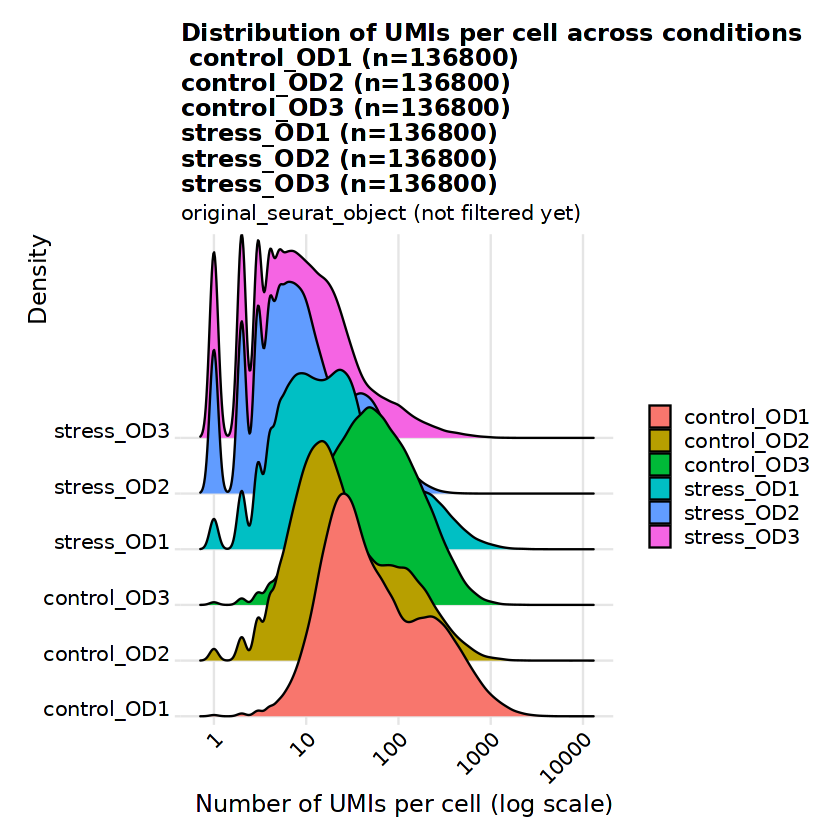

In [14]:
plots_with_point <- generate_qc_plots(
    seurat_obj = seurat_obj,
    subtitle = "original_seurat_object (not filtered yet)",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = TRUE
)

# Afficher les plots
plots_with_point$p1
plots_with_point$p2
plots_with_point$scatter_p3
plots_with_point$ridge_p4


## Supplementary boxplot 

In [15]:
# Boxplot de nCount_RNA par Condition_OD_timepoint_Rep_bio

# p1  <- seurat_obj@meta.data |>
#   ggplot(aes(x = Condition_OD_timepoint_Rep_bio, y = nCount_RNA)) +
#   geom_boxplot(fill = "skyblue", outlier.color = "red") +
#   theme_bw() +
#   labs(
#     title = "Distribution of nCount_RNA by Sample_ID",
#     x = "Sample ID",
#     y = "nCount_RNA"
#   ) +
#   theme(axis.text.x = element_text(angle = 45, hjust = 1))


# p1

# # if you want to add jitter points to the boxplot
# p1+
#   geom_jitter(width = 0.2, size = 2, color = "black")


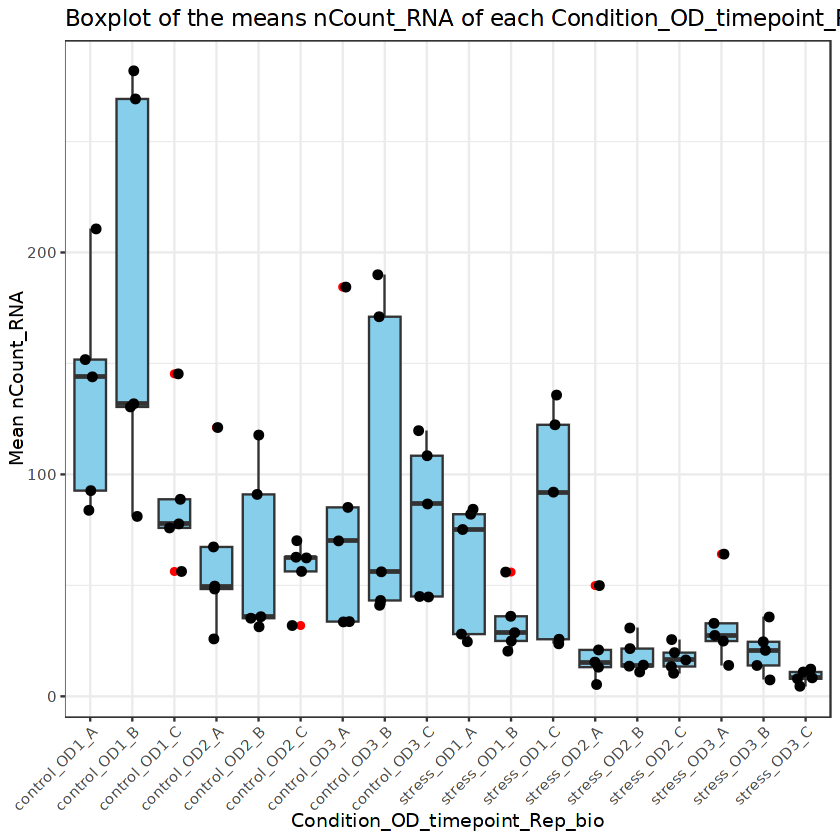

In [16]:
seurat_obj@meta.data %>%
  group_by(Condition_OD_timepoint_Rep_bio, , Sample_ID) %>%
  summarise(mean_nCount_RNA = mean(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint_Rep_bio, y = mean_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(width = 0.2, size = 2, color = "black") + # montre les points des Sample_ID
  theme_bw() +
  labs(
    title = "Boxplot of the means nCount_RNA of each Condition_OD_timepoint_Rep_bio (1 point = 1 repli tech)",
    x = "Condition_OD_timepoint_Rep_bio",
    y = "Mean nCount_RNA"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


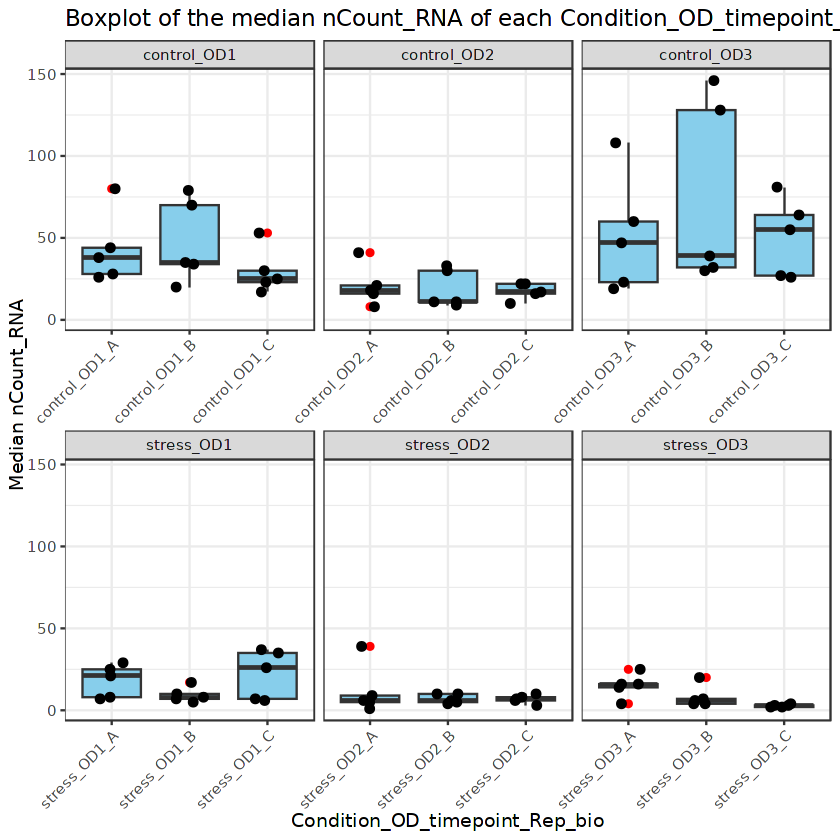

In [17]:
seurat_obj@meta.data %>%
  group_by(Condition_OD_timepoint_Rep_bio, Condition_OD_timepoint, Sample_ID) %>%
  summarise(median_nCount_RNA = median(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint_Rep_bio, y = median_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(width = 0.2, size = 2, color = "black") + # montre les points des Sample_ID
  theme_bw() +
  labs(
    title = "Boxplot of the median nCount_RNA of each Condition_OD_timepoint_Rep_bio (1 point = 1 repli tech)",
    x = "Condition_OD_timepoint_Rep_bio",
    y = "Median nCount_RNA"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  facet_wrap(~Condition_OD_timepoint, scales = "free_x")


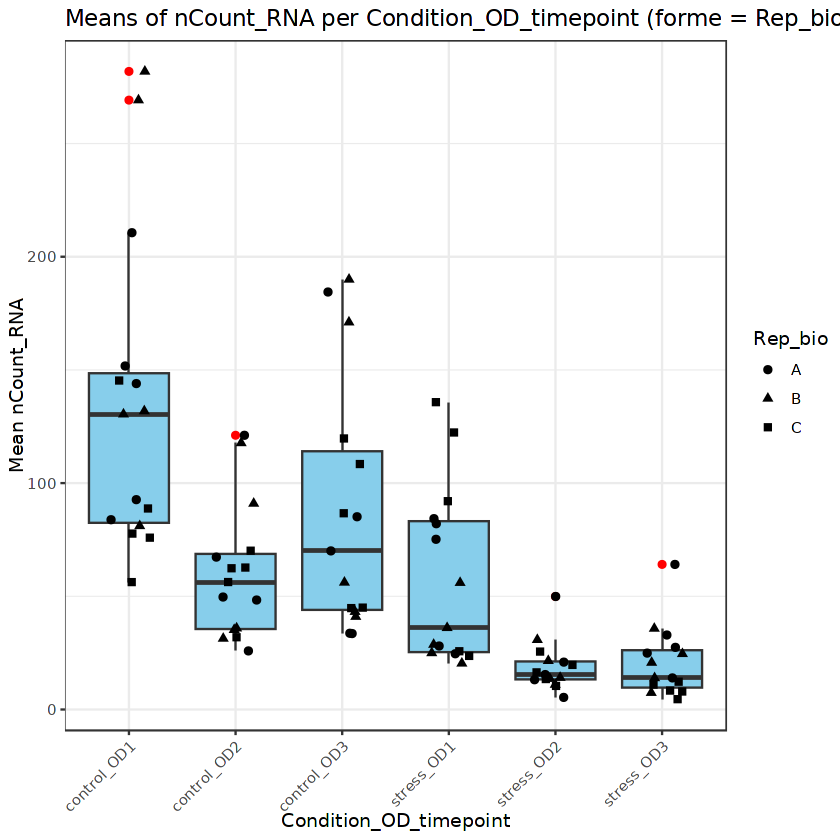

In [18]:
seurat_obj@meta.data %>%
  group_by(Condition_OD_timepoint, Sample_ID, Rep_bio) %>%
  summarise(mean_nCount_RNA = mean(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint, y = mean_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(aes(shape = Rep_bio), width = 0.2, size = 2, color = "black") +
  theme_bw() +
  labs(
    title = "Means of nCount_RNA per Condition_OD_timepoint (forme = Rep_bio)",
    x = "Condition_OD_timepoint",
    y = "Mean nCount_RNA",
    shape = "Rep_bio"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


In [19]:
# Afficher les cellules ayant le plus de nCount_RNA avant le filtrage (dans seurat_obj)
top_cells_nCount <- seurat_obj@meta.data %>%
    arrange(desc(nCount_RNA)) %>%
    head(20)

View(top_cells_nCount)

# Afficher les cellules ayant le plus de nFeature_RNA avant le filtrage (dans seurat_obj)
top_cells_nFeature <- seurat_obj@meta.data %>%
    arrange(desc(nFeature_RNA)) %>%
    head(20)

View(top_cells_nFeature)

# check if there are common cells in both top cells
common_cells <- intersect(rownames(top_cells_nCount), rownames(top_cells_nFeature))
cat("\nCommon cells in both top nCount and top nFeature:\n")
print(common_cells)


,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
GCTAACGA_ATCCTGTA_GCAAATTC,9452.001,1971,GCAAATTC,ATCCTGTA,GCTAACGA,G11,C4,E4,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
CAACCACA_GTCTGTCA_TTCATCGC,6404.000,1508,TTCATCGC,GTCTGTCA,CAACCACA,G2,E10,C6,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B
ATAGCGAC_CCAGTTCA_GCAAATTC,5812.999,1520,GCAAATTC,CCAGTTCA,ATAGCGAC,G11,C12,G8,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
GGTGCGAA_AACGTGAT_TTCATCGC,4945.999,1321,TTCATCGC,AACGTGAT,GGTGCGAA,G2,A1,E7,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B
CACCTTAC_TGAAGAGA_GTGGGTTC,4884.000,1359,GTGGGTTC,TGAAGAGA,CACCTTAC,H2,F4,G12,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
TCCGTCTA_CAGCGTTA_TCTTAATC,4466.000,1270,TCTTAATC,CAGCGTTA,TCCGTCTA,G6,C10,F2,M9F_C_3_OD2,M9F,C,3,OD2,0.5,0.603,control,control_OD2,C_3,control_OD2_C
ACATTGGC_TCTTCACA_GTGGGTTC,4289.000,1277,GTGGGTTC,TCTTCACA,ACATTGGC,H2,F3,A6,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
CACTTCGA_AGTACAAG_GTGGGTTC,4250.000,1212,GTGGGTTC,AGTACAAG,CACTTCGA,H2,A12,C9,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
TTCACGCA_AACCGAGA_TTCATCGC,4242.000,1194,TTCATCGC,AACCGAGA,TTCACGCA,G2,B2,F8,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B


,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
GCTAACGA_ATCCTGTA_GCAAATTC,9452.001,1971,GCAAATTC,ATCCTGTA,GCTAACGA,G11,C4,E4,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
ATAGCGAC_CCAGTTCA_GCAAATTC,5812.999,1520,GCAAATTC,CCAGTTCA,ATAGCGAC,G11,C12,G8,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
CAACCACA_GTCTGTCA_TTCATCGC,6404.000,1508,TTCATCGC,GTCTGTCA,CAACCACA,G2,E10,C6,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B
CACCTTAC_TGAAGAGA_GTGGGTTC,4884.000,1359,GTGGGTTC,TGAAGAGA,CACCTTAC,H2,F4,G12,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
GGTGCGAA_AACGTGAT_TTCATCGC,4945.999,1321,TTCATCGC,AACGTGAT,GGTGCGAA,G2,A1,E7,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B
ACATTGGC_TCTTCACA_GTGGGTTC,4289.000,1277,GTGGGTTC,TCTTCACA,ACATTGGC,H2,F3,A6,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
TCCGTCTA_CAGCGTTA_TCTTAATC,4466.000,1270,TCTTAATC,CAGCGTTA,TCCGTCTA,G6,C10,F2,M9F_C_3_OD2,M9F,C,3,OD2,0.5,0.603,control,control_OD2,C_3,control_OD2_C
GCTAACGA_ACACAGAA_GTGGGTTC,4209.000,1220,GTGGGTTC,ACACAGAA,GCTAACGA,H2,B6,E4,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
TGAAGAGA_CCTCTATC_GTGGGTTC,4038.000,1220,GTGGGTTC,CCTCTATC,TGAAGAGA,H2,H4,F4,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B



Common cells in both top nCount and top nFeature:
 [1] "GCTAACGA_ATCCTGTA_GCAAATTC" "CAACCACA_GTCTGTCA_TTCATCGC"
 [3] "ATAGCGAC_CCAGTTCA_GCAAATTC" "GGTGCGAA_AACGTGAT_TTCATCGC"
 [5] "CACCTTAC_TGAAGAGA_GTGGGTTC" "TCCGTCTA_CAGCGTTA_TCTTAATC"
 [7] "ACATTGGC_TCTTCACA_GTGGGTTC" "CACTTCGA_AGTACAAG_GTGGGTTC"
 [9] "TTCACGCA_AACCGAGA_TTCATCGC" "GCTAACGA_ACACAGAA_GTGGGTTC"
[11] "TCCGTCTA_CCTAATCC_GTGGGTTC" "GATGAATC_TGGTGGTA_TTCATCGC"
[13] "TGAAGAGA_CCTCTATC_GTGGGTTC" "GACAGTGC_CCATCCTC_TTCATCGC"
[15] "TATCAGCA_GACTAGTA_GTGGGTTC" "ACCTCCAA_AATCCGTC_CTGTCCCG"
[17] "CGACTGGA_ATTGAGGA_TTCATCGC" "ACGTATCA_GAGCTGAA_GTGGGTTC"
[19] "CCTCCTGA_CCTCTATC_TTCATCGC"


In [20]:
top_cells_nCount <- seurat_obj@meta.data %>%
    group_by(Sample_ID) %>%
    arrange(desc(nCount_RNA)) %>%
    slice_head(n = 3) %>%
    ungroup()

View(top_cells_nCount)


nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
3567.0000,1095,CTGCTTTG,AACTCACC,GAGCTGAA,E1,F9,D12,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
2785.9999,894,CTGCTTTG,AATGTTGC,GATGAATC,E1,G1,H11,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
2545.9999,891,CTGCTTTG,GAGCTGAA,ACTATGCA,E1,D12,B11,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
828.0000,420,CCGAGAAA,CCAGTTCA,CCTAATCC,E4,C12,H3,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
812.9999,394,CCGAGAAA,CCATCCTC,CGCATACA,E4,H1,D6,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
789.0001,402,CCGAGAAA,CCATCCTC,ACCTCCAA,E4,H1,B8,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
1473.9999,577,TATTTAAG,CTAAGGTC,CAACCACA,E7,H7,C6,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
1087.0000,497,TATTTAAG,TCCGTCTA,TCCGTCTA,E7,F2,F2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
942.9999,423,TATTTAAG,CCTAATCC,GCCACATA,E7,H3,E2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A


In [21]:
top_cells_nCount <- seurat_obj@meta.data %>%
    group_by(Sample_ID) %>%
    arrange(desc(nFeature_RNA)) %>%
    slice_head(n = 3) %>%
    ungroup()

View(top_cells_nCount)


nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
3567.0000,1095,CTGCTTTG,AACTCACC,GAGCTGAA,E1,F9,D12,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
2785.9999,894,CTGCTTTG,AATGTTGC,GATGAATC,E1,G1,H11,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
2545.9999,891,CTGCTTTG,GAGCTGAA,ACTATGCA,E1,D12,B11,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
828.0000,420,CCGAGAAA,CCAGTTCA,CCTAATCC,E4,C12,H3,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
789.0001,402,CCGAGAAA,CCATCCTC,ACCTCCAA,E4,H1,B8,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
812.9999,394,CCGAGAAA,CCATCCTC,CGCATACA,E4,H1,D6,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
1473.9999,577,TATTTAAG,CTAAGGTC,CAACCACA,E7,H7,C6,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
1087.0000,497,TATTTAAG,TCCGTCTA,TCCGTCTA,E7,F2,F2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
942.9999,423,TATTTAAG,CCTAATCC,GCCACATA,E7,H3,E2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A


## Filtrage Val 

### Fonction de filtrage 

In [22]:
select_cells_by_group <- function(seurat_obj,
                                  target_total_cells,
                                  group_by = "Condition",
                                  sort_by = "nCount_RNA",
                                  random = FALSE,
                                  seed = NULL,
                                  descending = TRUE) {
  # Vérification des colonnes
  meta <- seurat_obj@meta.data %>% rownames_to_column("cell_barcode")
  if (!(group_by %in% colnames(meta))) stop(paste("Group column", group_by, "not found."))
  if (!(sort_by %in% colnames(meta))) stop(paste("Sort column", sort_by, "not found."))

  # Nombre de groupes et cible par groupe
  n_groups <- length(unique(meta[[group_by]]))
  target_per_group <- floor(target_total_cells / n_groups)

  cat("Target total cells:", target_total_cells, "\n")
  cat("Group column:", group_by, "-", n_groups, "groups\n")
  cat("Sort by:", sort_by, " | Descending:", descending, "\n")
  cat("Cells per group:", target_per_group, "\n")
  if (random && !is.null(seed)) cat("Random selection with seed:", seed, "\n")

  # Sélection cellule par groupe
  get_cells <- function(df_group, n_target) {
    n_available <- nrow(df_group)

    if (n_available <= n_target) {
      message("Group ", unique(df_group[[group_by]]), ": only ", n_available, " cells available — keeping all.")
      return(df_group$cell_barcode)
    } else {
      if (random) {
        if (!is.null(seed)) set.seed(seed)
        return(sample(df_group$cell_barcode, size = n_target))
      } else {
        sorted_df <- if (descending) {
          df_group %>% arrange(desc(.data[[sort_by]]))
        } else {
          df_group %>% arrange(.data[[sort_by]])
        }
        return(sorted_df %>%
          slice_head(n = n_target) %>%
          pull(cell_barcode))
      }
    }
  }

  # Application par groupe
  selected_cells <- meta %>%
    group_by(.data[[group_by]]) %>%
    group_split() %>%
    map(~ get_cells(.x, target_per_group)) %>%
    unlist()

  # Sous-échantillonnage
  seurat_filtered <- subset(seurat_obj, cells = selected_cells)

  # Résumé
  summary_stats <- seurat_filtered@meta.data %>%
    group_by(.data[[group_by]]) %>%
    summarise(n_cells = n(), .groups = "drop")

  return(list(seurat = seurat_filtered, summary = summary_stats))
}


In [23]:
summary_stats <- seurat_obj@meta.data %>%
    summarise(n_cells = n())
View(summary_stats)


n_cells_total <- ncol(seurat_obj)
cat("Total number of cells in the original Seurat object:", n_cells_total, "\n")


n_cells
<int>
820800


Total number of cells in the original Seurat object: 820800 


### Fitrage select 10% of the cells with the top nFeature_RNA

In [24]:
# 820800 cell in total , i want to select 10% of the cells with the top nFeature_RNA

result_filter1 <- select_cells_by_group(
  seurat_obj = seurat_obj,
  target_total_cells = 82080,
  group_by = "Sample_ID",
  sort_by = "nFeature_RNA",
  descending = TRUE,
)


Target total cells: 82080 
Group column: Sample_ID - 90 groups
Sort by: nFeature_RNA  | Descending: TRUE 
Cells per group: 912 


In [25]:
# same by Sample

seurat_obj_filter1 <- result_filter1$seurat
summary_stats_sample <- seurat_obj_filter1@meta.data %>%
    group_by(Sample_ID) %>%
    summarise(
        n_cells = n(),
        min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE)
    )

View(summary_stats_sample)
# Save the summary statistics to a CSV file
# write.csv(summary_stats_sample, file = "summary_stats_by_Sample_ID.csv", row.names = FALSE)


Sample_ID,n_cells,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
M9F_A_1_OD1,912,486.0000,619.9999,742.5000,972.2500,3567.000,345.37647,278,310.75,393.30702,359.0,443.00,1095,111.82254
M9F_A_1_OD2,912,111.0000,150.0000,179.0000,226.0000,828.000,88.68557,90,102.00,129.52303,116.0,143.00,420,42.86283
M9F_A_1_OD3,912,157.0000,211.0000,244.5000,303.0000,1474.000,113.40194,116,129.00,160.25439,144.0,174.00,577,50.06745
M9F_A_2_OD1,912,200.0000,273.0000,327.0000,420.2500,1413.000,149.71734,142,162.00,204.38596,186.0,229.25,596,62.17221
M9F_A_2_OD2,912,284.0000,385.0000,481.0000,644.2500,2149.000,282.06786,187,216.00,289.46820,258.0,323.00,794,102.92835
M9F_A_2_OD3,912,58.0000,86.0000,99.0000,122.2500,441.000,38.82897,55,60.00,74.34211,68.0,81.00,217,20.41085
M9F_A_3_OD1,912,220.0000,296.7500,357.0000,482.0000,1710.000,195.51314,149,173.00,226.76535,202.0,255.00,673,78.26649
M9F_A_3_OD2,912,55.0000,84.0000,106.0000,139.0000,801.000,73.39907,55,63.00,87.90351,75.0,96.00,424,38.59642
M9F_A_3_OD3,912,388.0000,498.0000,587.4999,767.7499,2230.000,261.43045,233,260.00,328.46162,299.0,368.25,794,93.77421


### remove potential doublets

In [26]:
# remove potential doublets
seurat_obj_Rm_doublets <- subset(seurat_obj_filter1, subset = nCount_RNA < 5000 & nFeature_RNA < 1500)

# nombre de cellules dans l'objet Seurat non filtré
n_cells_total <- ncol(seurat_obj_filter1)
cat("Total number of cells in the original Seurat object:", n_cells_total, "\n")
# nombre de cellules dans l'objet Seurat filtré
n_cells_filtered <- ncol(seurat_obj_Rm_doublets)
cat("Number of cells in the filtered Seurat object:", n_cells_filtered, "\n")


Total number of cells in the original Seurat object: 82080 
Number of cells in the filtered Seurat object: 82077 


In [27]:
### filter by Ncount to keep approximately 3000 cells in total

result_filter2 <- select_cells_by_group(
  seurat_obj = seurat_obj_Rm_doublets,
  target_total_cells = 3000,
  group_by = "Sample_ID",
  sort_by = "nCount_RNA",
  descending = TRUE,
)
n_cells_total <- ncol(result_filter2$seurat)
cat("Total number of cells in the original Seurat object:", n_cells_total, "\n")


Target total cells: 3000 
Group column: Sample_ID - 90 groups
Sort by: nCount_RNA  | Descending: TRUE 
Cells per group: 33 
Total number of cells in the original Seurat object: 2970 


In [28]:
# same by Sample

seurat_obj_filter2 <- result_filter2$seurat
summary_stats_sample <- seurat_obj_filter2@meta.data %>%
    group_by(Sample_ID) %>%
    summarise(
        n_cells = n(),
        min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE)
    )

View(summary_stats_sample)
# Save the summary statistics to a CSV file
# write.csv(summary_stats_sample, file = "summary_stats_by_Sample_ID.csv", row.names = FALSE)


Sample_ID,n_cells,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>
M9F_A_1_OD1,33,1649.0000,1796.0000,1929.0000,2164.0001,3567.000,391.89275,642,673,749.2424,732,769,1095,94.15613
M9F_A_1_OD2,33,435.0000,457.0000,478.9999,554.0000,828.000,108.44842,230,253,279.8182,260,300,420,47.58575
M9F_A_1_OD3,33,539.0000,577.0000,633.9999,771.0000,1474.000,189.22029,266,293,343.0303,326,375,577,67.21862
M9F_A_2_OD1,33,701.0000,740.0000,817.0000,1001.0000,1413.000,215.93569,322,360,417.3333,391,446,596,76.81539
M9F_A_2_OD2,33,1245.0000,1345.9999,1524.0001,1702.0000,2149.000,277.29012,521,557,628.3333,614,684,794,81.13248
M9F_A_2_OD3,33,203.0000,215.0000,225.0000,258.0000,441.000,49.44001,116,131,144.2424,136,154,217,23.04890
M9F_A_3_OD1,33,859.0000,947.0000,1038.9999,1248.0000,1710.000,237.81904,408,440,490.3030,463,523,673,75.07308
M9F_A_3_OD2,33,308.0000,336.0000,370.9999,434.0000,801.000,107.86036,174,199,226.2424,217,239,424,50.69519
M9F_A_3_OD3,33,1232.9999,1395.0000,1489.9999,1741.0000,2230.000,278.37542,506,577,631.6364,611,669,794,76.59423


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


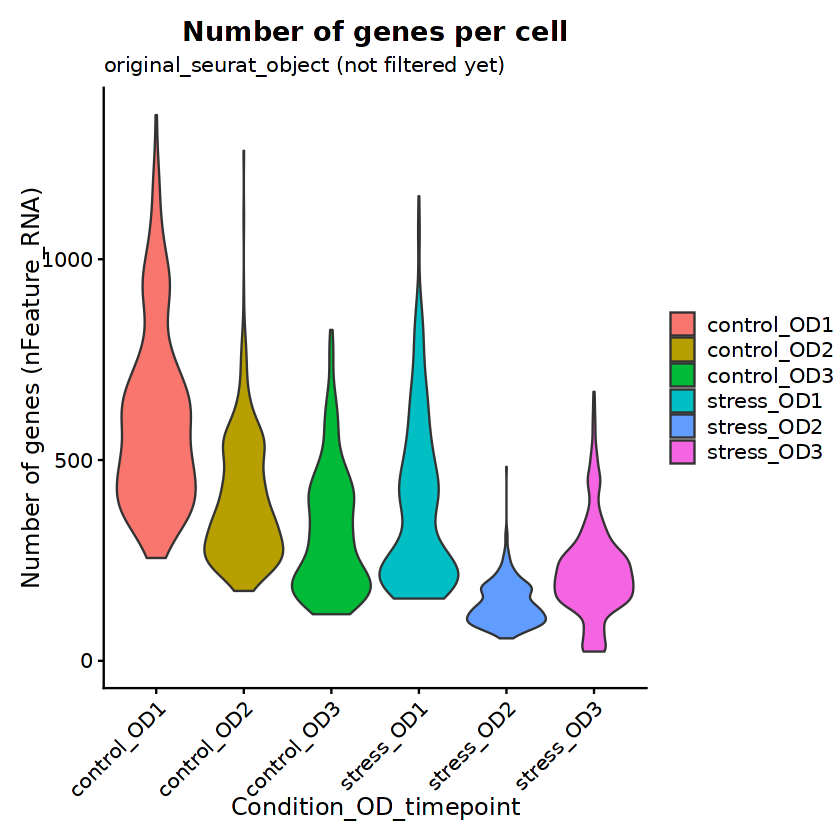

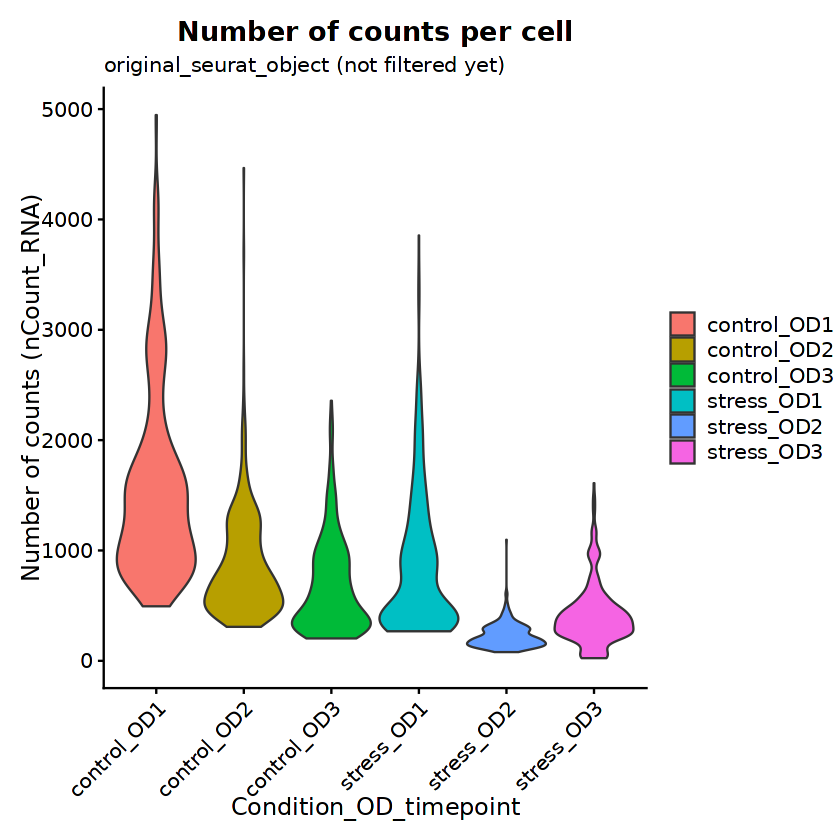

Picking joint bandwidth of 0.0603



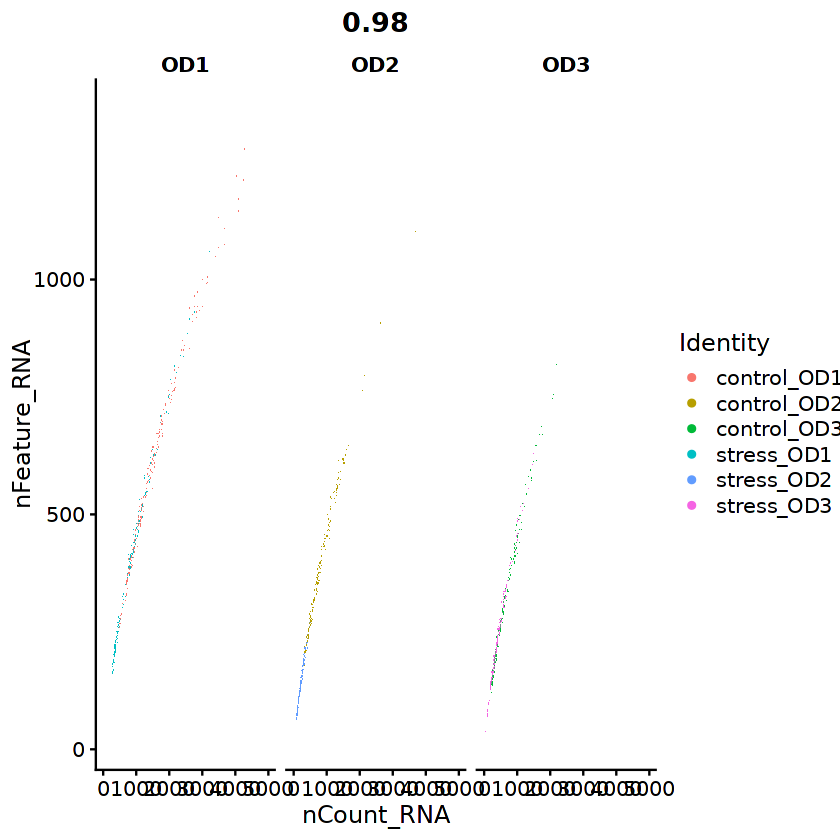

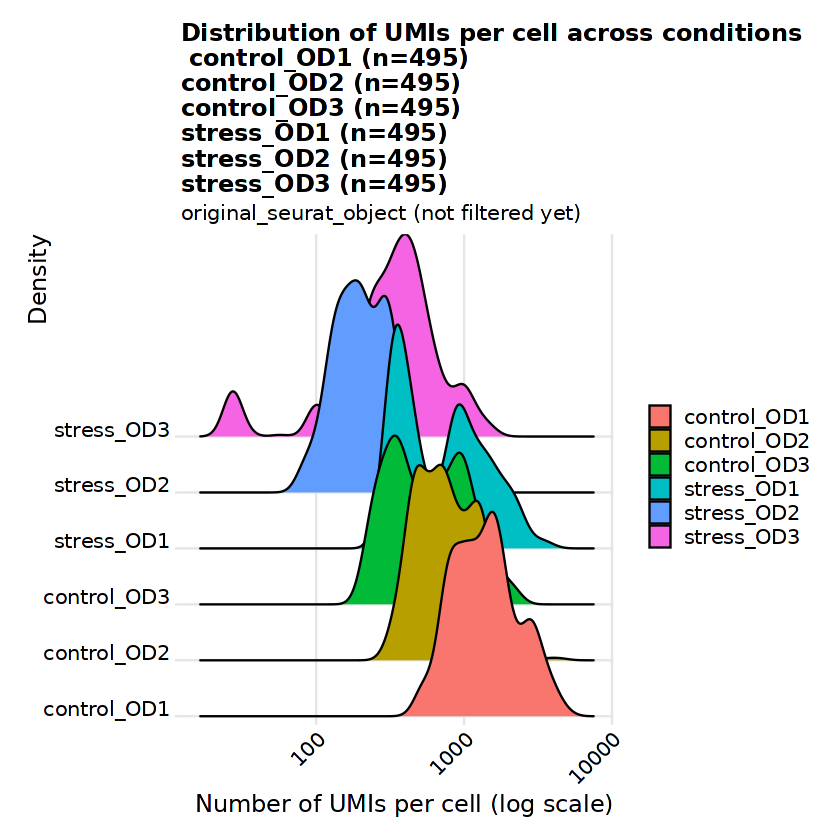

In [29]:
plots_without_point <- generate_qc_plots(
    seurat_obj = seurat_obj_filter2,
    subtitle = "original_seurat_object (not filtered yet)",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = FALSE
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


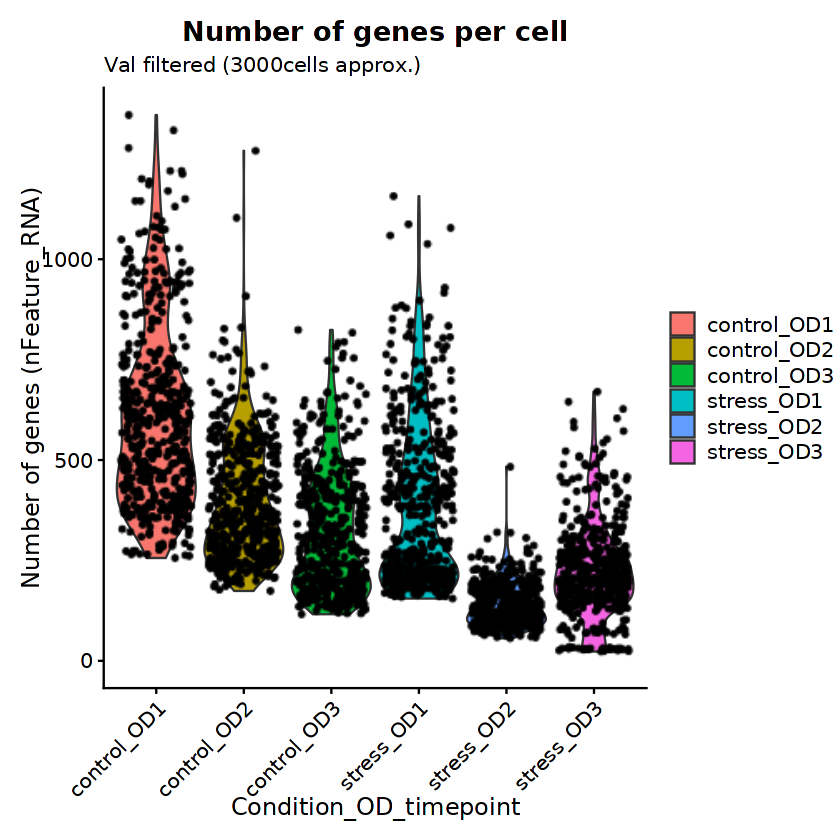

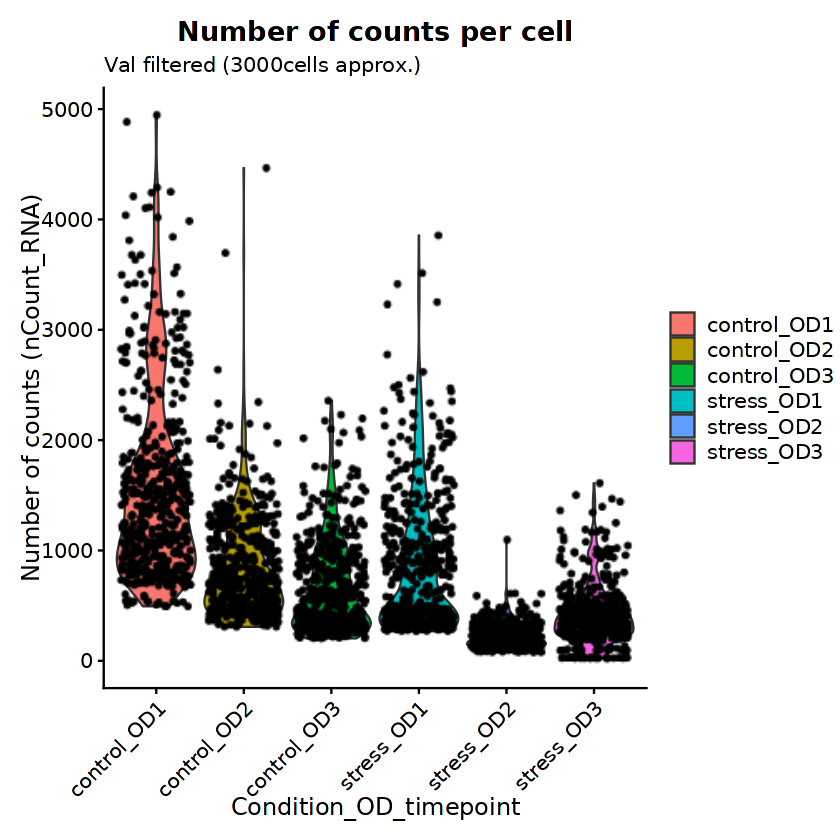

Picking joint bandwidth of 0.0603



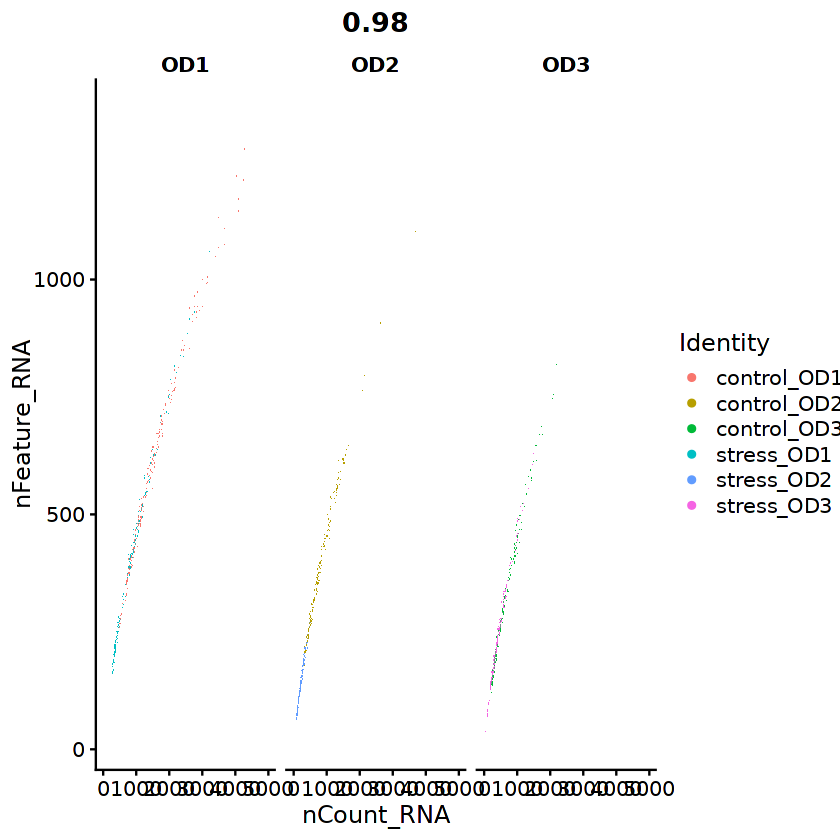

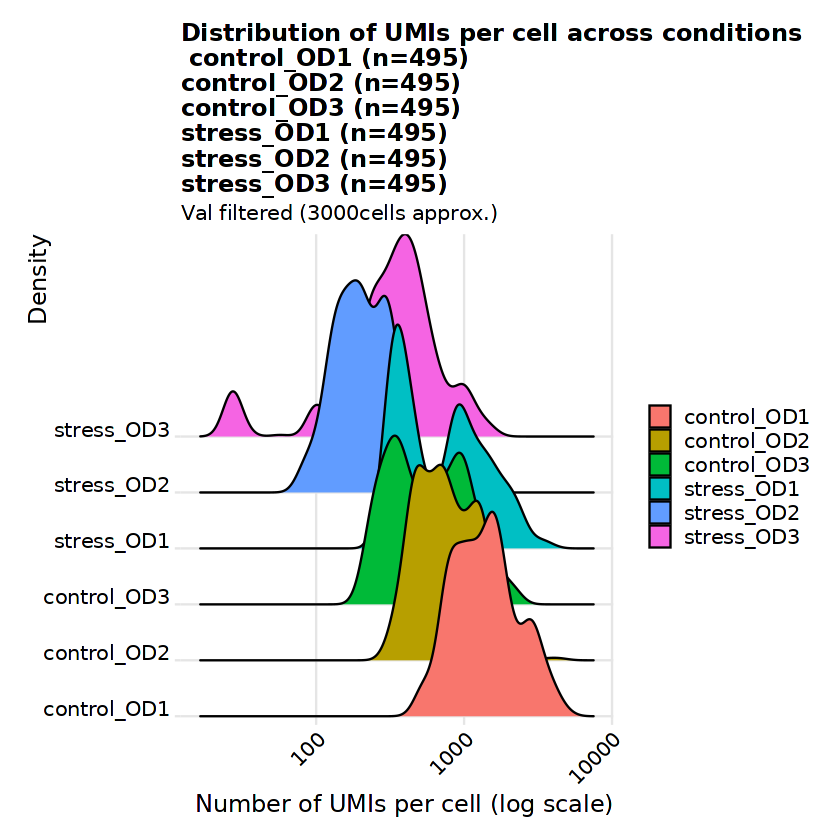

In [30]:
plots_with_point <- generate_qc_plots(
    seurat_obj = seurat_obj_filter2,
    subtitle = "Val filtered (3000cells approx.)",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = TRUE
)

# Afficher les plots
plots_with_point$p1
plots_with_point$p2
plots_with_point$scatter_p3
plots_with_point$ridge_p4


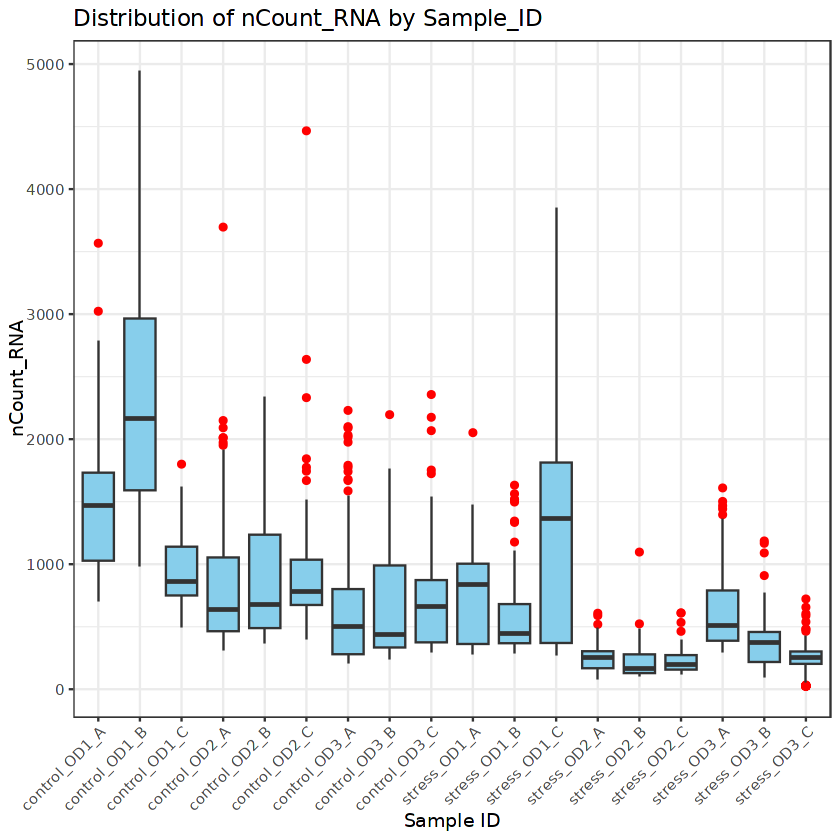

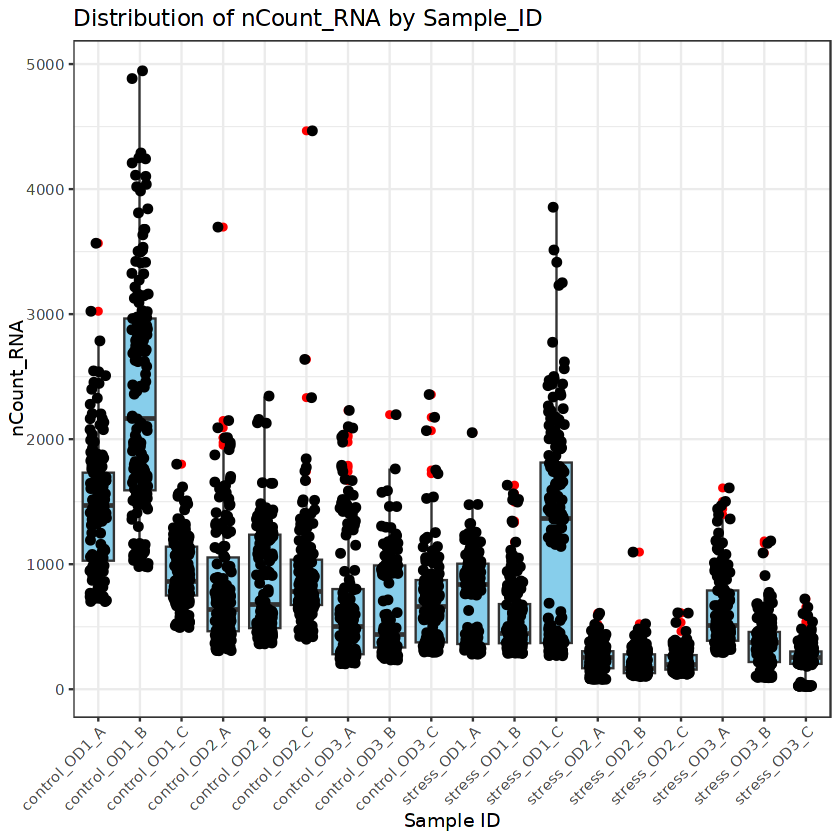

In [31]:
# Boxplot de nCount_RNA par Condition_OD_timepoint_Rep_bio

p1 <- seurat_obj_filter2@meta.data |>
  ggplot(aes(x = Condition_OD_timepoint_Rep_bio, y = nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  theme_bw() +
  labs(
    title = "Distribution of nCount_RNA by Sample_ID",
    x = "Sample ID",
    y = "nCount_RNA"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


p1

# if you want to add jitter points to the boxplot
p1 +
  geom_jitter(width = 0.2, size = 2, color = "black")


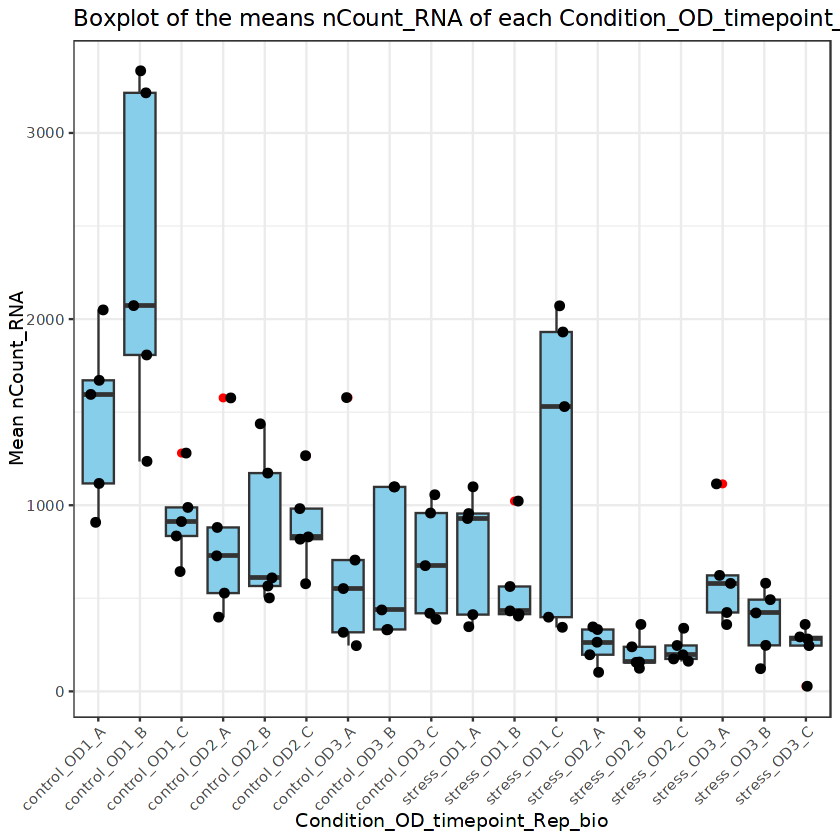

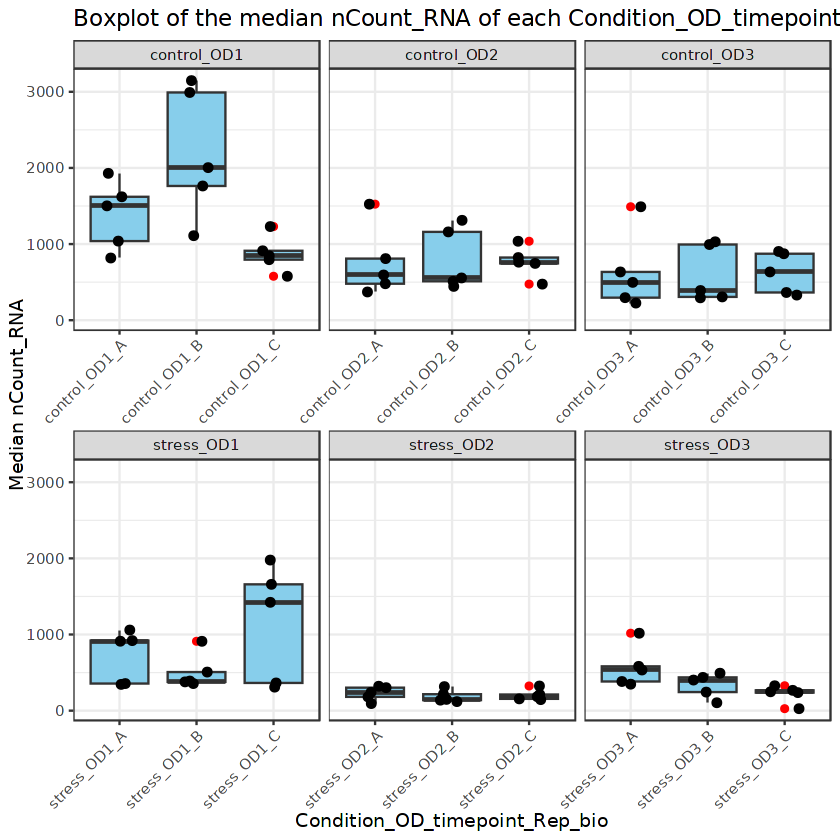

In [32]:
seurat_obj_filter2@meta.data %>%
  group_by(Condition_OD_timepoint_Rep_bio, , Sample_ID) %>%
  summarise(mean_nCount_RNA = mean(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint_Rep_bio, y = mean_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(width = 0.2, size = 2, color = "black") + # montre les points des Sample_ID
  theme_bw() +
  labs(
    title = "Boxplot of the means nCount_RNA of each Condition_OD_timepoint_Rep_bio (1 point = 1 repli tech)",
    x = "Condition_OD_timepoint_Rep_bio",
    y = "Mean nCount_RNA"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


seurat_obj_filter2@meta.data %>%
  group_by(Condition_OD_timepoint_Rep_bio, Condition_OD_timepoint, Sample_ID) %>%
  summarise(median_nCount_RNA = median(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint_Rep_bio, y = median_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(width = 0.2, size = 2, color = "black") + # montre les points des Sample_ID
  theme_bw() +
  labs(
    title = "Boxplot of the median nCount_RNA of each Condition_OD_timepoint_Rep_bio (1 point = 1 repli tech)",
    x = "Condition_OD_timepoint_Rep_bio",
    y = "Median nCount_RNA"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  facet_wrap(~Condition_OD_timepoint, scales = "free_x")


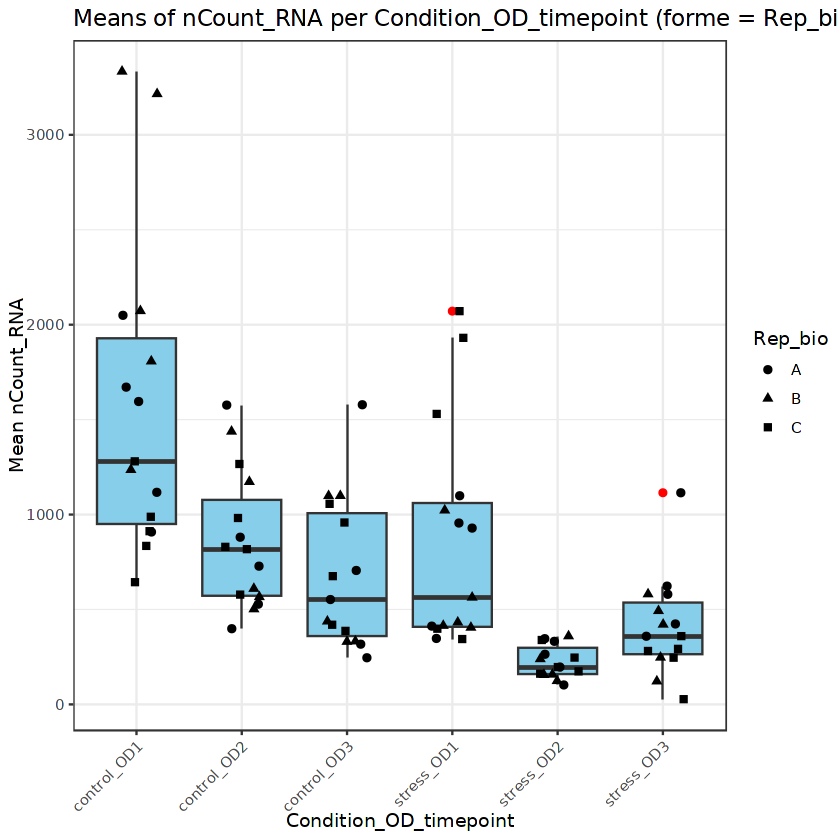

In [33]:
seurat_obj_filter2@meta.data %>%
  group_by(Condition_OD_timepoint, Sample_ID, Rep_bio) %>%
  summarise(mean_nCount_RNA = mean(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint, y = mean_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(aes(shape = Rep_bio), width = 0.2, size = 2, color = "black") +
  theme_bw() +
  labs(
    title = "Means of nCount_RNA per Condition_OD_timepoint (forme = Rep_bio)",
    x = "Condition_OD_timepoint",
    y = "Mean nCount_RNA",
    shape = "Rep_bio"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


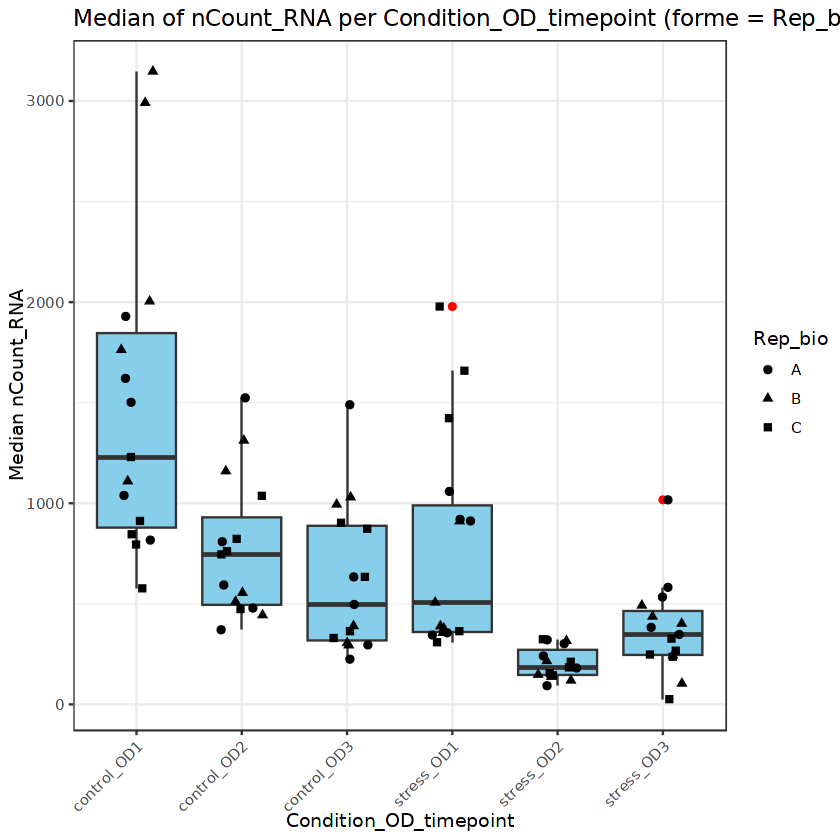

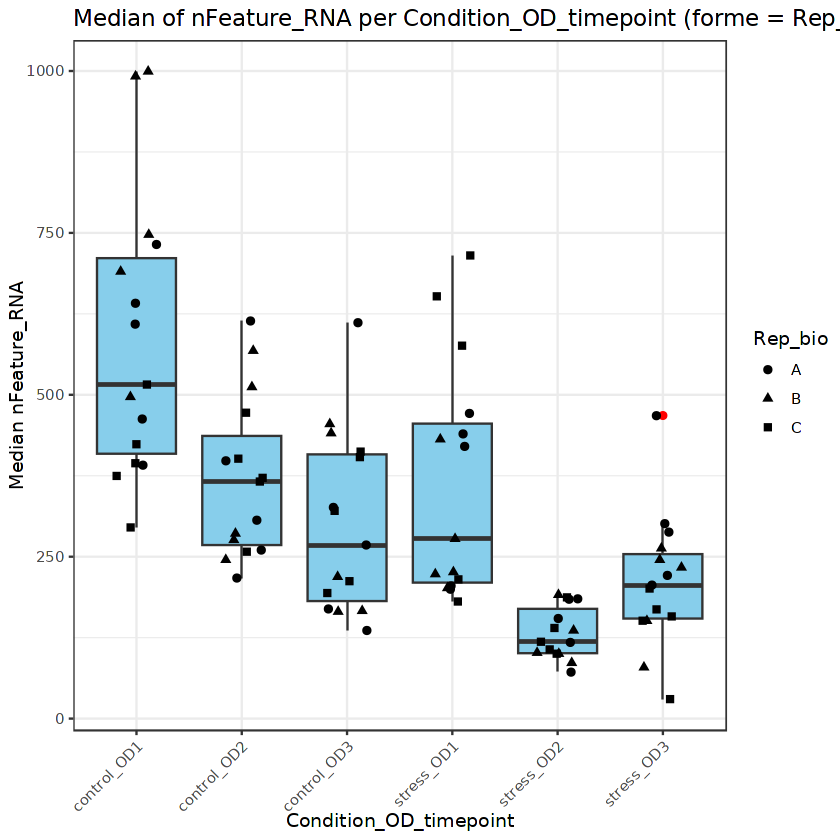

In [34]:
seurat_obj_filter2@meta.data %>%
  group_by(Condition_OD_timepoint, Sample_ID, Rep_bio) %>%
  summarise(median_nCount_RNA = median(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint, y = median_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(aes(shape = Rep_bio), width = 0.2, size = 2, color = "black") +
  theme_bw() +
  labs(
    title = "Median of nCount_RNA per Condition_OD_timepoint (forme = Rep_bio)",
    x = "Condition_OD_timepoint",
    y = "Median nCount_RNA",
    shape = "Rep_bio"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


seurat_obj_filter2@meta.data %>%
  group_by(Condition_OD_timepoint, Sample_ID, Rep_bio) %>%
  summarise(median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint, y = median_nFeature_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(aes(shape = Rep_bio), width = 0.2, size = 2, color = "black") +
  theme_bw() +
  labs(
    title = "Median of nFeature_RNA per Condition_OD_timepoint (forme = Rep_bio)",
    x = "Condition_OD_timepoint",
    y = "Median nFeature_RNA",
    shape = "Rep_bio"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


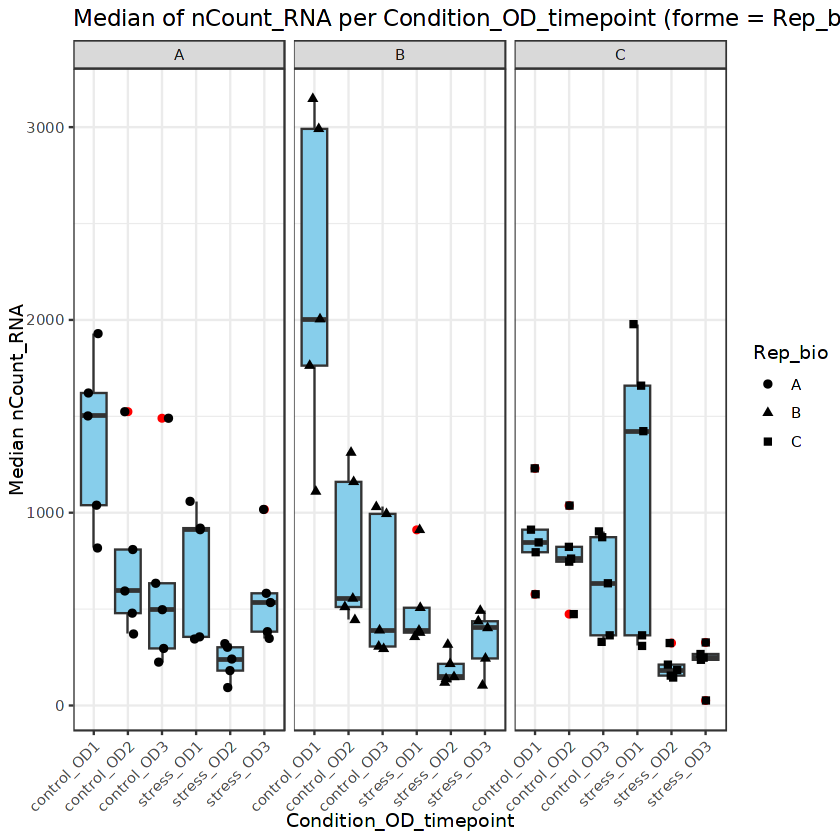

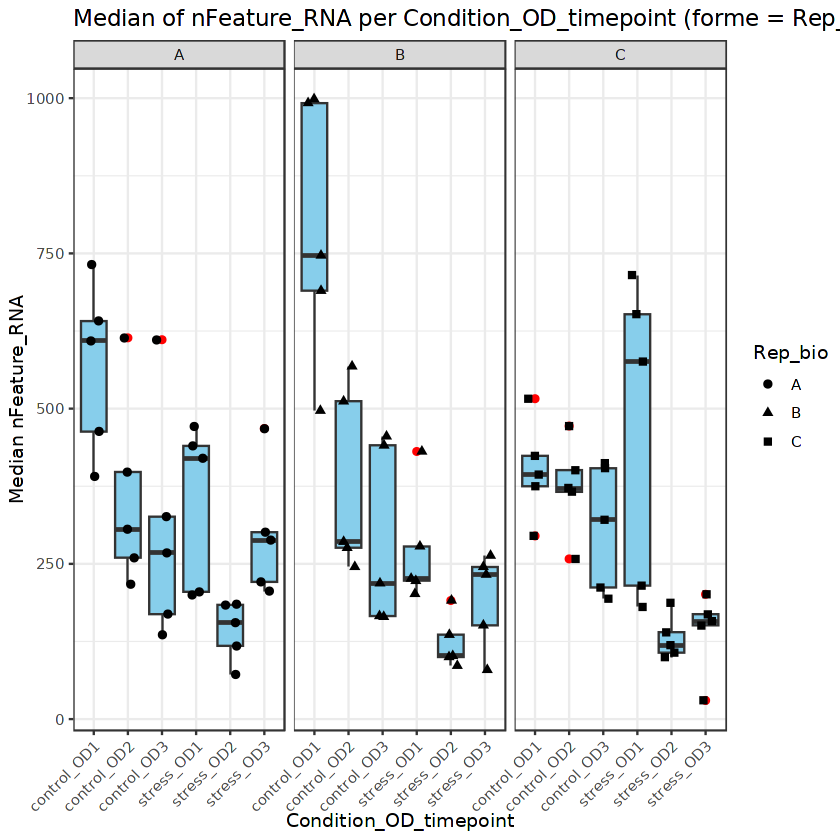

In [35]:
seurat_obj_filter2@meta.data %>%
  group_by(Condition_OD_timepoint, Sample_ID, Rep_bio) %>%
  summarise(median_nCount_RNA = median(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint, y = median_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(aes(shape = Rep_bio), width = 0.2, size = 2, color = "black") +
  theme_bw() +
  labs(
    title = "Median of nCount_RNA per Condition_OD_timepoint (forme = Rep_bio)",
    x = "Condition_OD_timepoint",
    y = "Median nCount_RNA",
    shape = "Rep_bio"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  facet_wrap(~Rep_bio, scales = "free_x")




seurat_obj_filter2@meta.data %>%
  group_by(Condition_OD_timepoint, Sample_ID, Rep_bio) %>%
  summarise(median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint, y = median_nFeature_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(aes(shape = Rep_bio), width = 0.2, size = 2, color = "black") +
  theme_bw() +
  labs(
    title = "Median of nFeature_RNA per Condition_OD_timepoint (forme = Rep_bio)",
    x = "Condition_OD_timepoint",
    y = "Median nFeature_RNA",
    shape = "Rep_bio"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  facet_wrap(~Rep_bio, scales = "free_x")


il y a un des replica technique de stress OD3 C qui a une expression très faible(nCount et nFeature très faible) , peut etre un probleme de pipetage => à vérifier après

In [36]:
# same by Sample
summary_stats_sample <- seurat_obj_filter2@meta.data %>%
    group_by(Sample_ID) %>%
    summarise(
        n_cells = n(),
        min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE)
    )

View(summary_stats_sample)
# create a directory if it does not exist
dir.create("jupyter/correct/csv", recursive = TRUE, showWarnings = FALSE)
# Save the summary statistics to a CSV file
write.csv(summary_stats_sample, file = "jupyter/correct/csv/summary_stats_Val_filter_by_Sample_ID.csv", row.names = FALSE)


Sample_ID,n_cells,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>
M9F_A_1_OD1,33,1649.0000,1796.0000,1929.0000,2164.0001,3567.000,391.89275,642,673,749.2424,732,769,1095,94.15613
M9F_A_1_OD2,33,435.0000,457.0000,478.9999,554.0000,828.000,108.44842,230,253,279.8182,260,300,420,47.58575
M9F_A_1_OD3,33,539.0000,577.0000,633.9999,771.0000,1474.000,189.22029,266,293,343.0303,326,375,577,67.21862
M9F_A_2_OD1,33,701.0000,740.0000,817.0000,1001.0000,1413.000,215.93569,322,360,417.3333,391,446,596,76.81539
M9F_A_2_OD2,33,1245.0000,1345.9999,1524.0001,1702.0000,2149.000,277.29012,521,557,628.3333,614,684,794,81.13248
M9F_A_2_OD3,33,203.0000,215.0000,225.0000,258.0000,441.000,49.44001,116,131,144.2424,136,154,217,23.04890
M9F_A_3_OD1,33,859.0000,947.0000,1038.9999,1248.0000,1710.000,237.81904,408,440,490.3030,463,523,673,75.07308
M9F_A_3_OD2,33,308.0000,336.0000,370.9999,434.0000,801.000,107.86036,174,199,226.2424,217,239,424,50.69519
M9F_A_3_OD3,33,1232.9999,1395.0000,1489.9999,1741.0000,2230.000,278.37542,506,577,631.6364,611,669,794,76.59423


# Filtering of Genes in the Seurat Object

## Only keep mRNA (CDS)

In [37]:
# Filter to conserve only CDS genes in seq_type

cat("\nGene annotation information:\n")
cat("Number of features in Seurat object:", nrow(seurat_obj_filter2), "\n")


# use dplyr to summarize the feature metadata if available
if ("RNA" %in% names(seurat_obj_filter2@assays)) {
  feature_metadata <- seurat_obj_filter2[["RNA"]][[]]
  # Summarize each column using dplyr
  metadata_summary <- feature_metadata %>%
    summarise(across(everything(), ~ n_distinct(.)))
  cat("\nNumber of unique values in each feature annotation column:\n")
  print(metadata_summary)
  # Optionally, show unique values for specific columns if they exist
  if ("feature" %in% colnames(feature_metadata)) {
    cat("\nUnique values in feature column:\n")
    print(unique(feature_metadata$feature))
  }
}



Gene annotation information:


Number of features in Seurat object: 6248 

Number of unique values in each feature annotation column:
  seq_type feature class product_accession name symbol locus_tag
1        3       6     6              5974 3170   1186      6117

Unique values in feature column:
[1] "rRNA"  "tRNA"  "CDS"   "tmRNA" NA      "ncRNA"


In [38]:
# View the feature type distribution for CDS-filtered object
feature_metadata <- seurat_obj_filter2[["RNA"]][[]]

feature_summary <- feature_metadata %>%
    count(feature) %>%
    mutate(percentage = round(n / sum(n) * 100, 2)) %>%
    arrange(desc(n))

View(feature_summary)


feature,n,percentage
<chr>,<int>,<dbl>
CDS,6036,96.61
NA,132,2.11
tRNA,65,1.04
rRNA,11,0.18
ncRNA,3,0.05
tmRNA,1,0.02


In [39]:
filter_seurat_by_gene_type <- function(seurat_obj, gene_types_to_keep = c("CDS"), assay = "RNA") {
  cat("=== Loading Seurat object ===\n")

  # Extract feature metadata
  cat("Extracting gene metadata...\n")
  feature_metadata <- seurat_obj[[assay]][[]] %>%
    as.data.frame() %>%
    tibble::rownames_to_column("gene_name")

  # Show gene type distribution BEFORE filtering
  cat("\n--- Gene type distribution BEFORE filtering ---\n")
  feature_metadata %>%
    count(feature) %>%
    mutate(percentage = round(n / sum(n) * 100, 2)) %>%
    arrange(desc(n)) %>%
    print()

  # Filter genes
  cat("\nFiltering genes by types:", paste(gene_types_to_keep, collapse = ", "), "\n")
  genes_to_keep <- feature_metadata %>%
    filter(feature %in% gene_types_to_keep) %>%
    pull(gene_name)

  cat("Number of genes to keep:", length(genes_to_keep), "\n")

  # Show gene type distribution AFTER filtering
  cat("\n--- Gene type distribution AFTER filtering ---\n")
  feature_metadata %>%
    filter(feature %in% gene_types_to_keep) %>%
    count(feature) %>%
    print()

  # Create filtered Seurat object
  cat("\nCreating filtered Seurat object...\n")
  seurat_filtered <- subset(seurat_obj, features = genes_to_keep)

  # Display filtering stats
  cat("\n--- Filtered Seurat object statistics ---\n")
  cat("Number of cells:", ncol(seurat_filtered), "\n")
  cat("Number of genes:", nrow(seurat_filtered), "\n")

  # Show metadata info
  cat("\n--- Metadata overview ---\n")
  cat("Dimensions:", dim(seurat_filtered@meta.data), "\n")
  cat("Columns:", paste(colnames(seurat_filtered@meta.data), collapse = ", "), "\n")
  cat("First 6 rows:\n")
  print(head(seurat_filtered@meta.data))

  # Summary of filtering
  cat("\n--- Filtering summary ---\n")
  cat("Original object - Genes:", nrow(seurat_obj), " | Cells:", ncol(seurat_obj), "\n")
  cat("Filtered object - Genes:", nrow(seurat_filtered), " | Cells:", ncol(seurat_filtered), "\n")
  cat("Genes removed:", nrow(seurat_obj) - nrow(seurat_filtered), "\n")
  cat("Reduction in gene count:", round((1 - nrow(seurat_filtered) / nrow(seurat_obj)) * 100, 2), "%\n")

  # Gene type distribution in final object
  cat("\n--- Gene type distribution in the filtered object ---\n")
  feature_metadata %>%
    filter(gene_name %in% rownames(seurat_filtered)) %>%
    count(feature) %>%
    mutate(percentage = round(n / sum(n) * 100, 2)) %>%
    print()

  cat("\nFiltering completed successfully.\n")
  return(seurat_filtered)
}


In [40]:
seurat_obj_filter2_CDS <- filter_seurat_by_gene_type(seurat_obj_filter2, gene_types_to_keep = c("CDS"))


=== Loading Seurat object ===
Extracting gene metadata...

--- Gene type distribution BEFORE filtering ---
  feature    n percentage
1     CDS 6036      96.61
2    <NA>  132       2.11
3    tRNA   65       1.04
4    rRNA   11       0.18
5   ncRNA    3       0.05
6   tmRNA    1       0.02

Filtering genes by types: CDS 
Number of genes to keep: 6036 

--- Gene type distribution AFTER filtering ---
  feature    n
1     CDS 6036

Creating filtered Seurat object...

--- Filtered Seurat object statistics ---
Number of cells: 2970 
Number of genes: 6036 

--- Metadata overview ---
Dimensions: 2970 19 
Columns: nCount_RNA, nFeature_RNA, barcode.rd1, barcode.rd2, barcode.rd3, Well_loc_rd1, Well_loc_rd2, Well_loc_rd3, Sample_ID, Culture_medium, Rep_bio, Rep_tech, OD_timepoint, OD_theoric, OD_measured, Condition, Condition_OD_timepoint, Rep, Condition_OD_timepoint_Rep_bio 
First 6 rows:
                           nCount_RNA nFeature_RNA barcode.rd1 barcode.rd2
GTACGCAA_AACCGAGA_AAACGATA        3

In [41]:
# View the feature type distribution for CDS-filtered object
feature_metadata <- seurat_obj_filter2_CDS[["RNA"]][[]]

feature_summary <- feature_metadata %>%
    count(feature) %>%
    mutate(percentage = round(n / sum(n) * 100, 2)) %>%
    arrange(desc(n))

View(feature_summary)


feature,n,percentage
<chr>,<int>,<dbl>
CDS,6036,100


## FIlter 

In [43]:
# test with 3 cells
min.cells <- 3
# Identify genes expressed in at least min.cells cells
counts <- GetAssayData(seurat_obj_filter2_CDS, layer = "counts")
genes_to_keep_5cell <- rowSums(counts > 0) >= min.cells

# Subset Seurat object
seurat_obj_filter2_CDS_3cells <- subset(seurat_obj_filter2_CDS, features = names(genes_to_keep_5cell[genes_to_keep_5cell]))

# Calculate statistics for 5 cells filter
cat("\n=== Statistics for seurat_obj_filter2_CDS_3cells (min 5 cells per gene) ===\n")
cat("\nnFeature_RNA statistics:\n")
print(summary(seurat_obj_filter2_CDS_3cells$nFeature_RNA))
cat("\nnCount_RNA statistics:\n")
print(summary(seurat_obj_filter2_CDS_3cells$nCount_RNA))
cat("\nNumber of cells:", ncol(seurat_obj_filter2_CDS_3cells), "\n")
cat("Number of genes:", nrow(seurat_obj_filter2_CDS_3cells), "\n")

removed_genes5cell <- nrow(seurat_obj_filter2_CDS) - nrow(seurat_obj_filter2_CDS_3cells)
cat("\nNumber of genes removed by filtering (min 5 cells):", removed_genes5cell, "\n")



=== Statistics for seurat_obj_filter2_CDS_3cells (min 5 cells per gene) ===

nFeature_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   23.0   185.0   280.0   345.1   464.0  1359.0 

nCount_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   24.0   315.0   532.0   768.5  1031.7  4946.0 

Number of cells: 2970 
Number of genes: 5584 

Number of genes removed by filtering (min 5 cells): 452 


In [44]:
# test with 5 cells
min.cells <- 5
# Identify genes expressed in at least min.cells cells
counts <- GetAssayData(seurat_obj_filter2_CDS, layer = "counts")
genes_to_keep_5cell <- rowSums(counts > 0) >= min.cells

# Subset Seurat object
seurat_obj_filter2_CDS_5cells <- subset(seurat_obj_filter2_CDS, features = names(genes_to_keep_5cell[genes_to_keep_5cell]))

# Calculate statistics for 5 cells filter
cat("\n=== Statistics for seurat_obj_filter2_CDS_5cells (min 5 cells per gene) ===\n")
cat("\nnFeature_RNA statistics:\n")
print(summary(seurat_obj_filter2_CDS_5cells$nFeature_RNA))
cat("\nnCount_RNA statistics:\n")
print(summary(seurat_obj_filter2_CDS_5cells$nCount_RNA))
cat("\nNumber of cells:", ncol(seurat_obj_filter2_CDS_5cells), "\n")
cat("Number of genes:", nrow(seurat_obj_filter2_CDS_5cells), "\n")

removed_genes5cell <- nrow(seurat_obj_filter2_CDS) - nrow(seurat_obj_filter2_CDS_5cells)
cat("\nNumber of genes removed by filtering (min 5 cells):", removed_genes5cell, "\n")



=== Statistics for seurat_obj_filter2_CDS_5cells (min 5 cells per gene) ===

nFeature_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   23.0   185.0   280.0   345.1   464.0  1359.0 

nCount_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   24.0   315.0   532.0   768.5  1031.7  4946.0 

Number of cells: 2970 
Number of genes: 5383 

Number of genes removed by filtering (min 5 cells): 653 


# Save filtered Object : Seurat object and Anndata object

## Save the RDS file 

In [45]:
saveRDS(seurat_obj_filter2, "jupyter/correct/ScObjects/SeuratObject_Val_Filtered.rds")
saveRDS(seurat_obj_filter2_CDS, "jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS.rds")
saveRDS(seurat_obj_filter2_CDS_3cells, "jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_3cells.rds")
saveRDS(seurat_obj_filter2_CDS_5cells, "jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_5cells.rds")


## Save the Anndata file

In [ ]:
adata <- convert_seurat_to_anndata(
  input_file = "jupyter/correct/ScObjects/SeuratObject_Val_Filtered.rds"
)
adata_CDS <- convert_seurat_to_anndata(
  input_file = "jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS.rds"
)
adata_CDS_3cells <- convert_seurat_to_anndata(
  input_file = "jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_3cells.rds"
)
adata_CDS_5cells <- convert_seurat_to_anndata(
  input_file = "jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_5cells.rds"
)
# Save the anndata objects


Reading RDS file: jupyter/correct/ScObjects/SeuratObject_Val_Filtered.rds

Converting to AnnData...

Output file: jupyter/correct/ScObjects/SeuratObject_Val_Filtered.h5ad

* Checking Seurat object validity
* Extracting Data from RNA assay to transfer to anndata.
* Creating anndata object.
* Writing anndata file:
  "/workspaces/microsplit_DOL/jupyter/correct/ScObjects/SeuratObject_Val_Filtered.h5ad"
Successfully converted to .h5ad: jupyter/correct/ScObjects/SeuratObject_Val_Filtered.h5ad

Verifying output .h5ad file...

Adding feature metadata using Python...

Reading updated AnnData object...

Columns present in AnnData's `var` (feature metadata):



[1] "names"             "seq_type"          "feature"          
[4] "class"             "product_accession" "name"             
[7] "symbol"            "locus_tag"        


The AnnData object is now ready in the variable `adata`.

You can continue your analysis in Python using Scanpy or other tools.

Reading RDS file: jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS.rds

Converting to AnnData...

Output file: jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS.h5ad

* Checking Seurat object validity
* Extracting Data from RNA assay to transfer to anndata.
* Creating anndata object.
* Writing anndata file:
  "/workspaces/microsplit_DOL/jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS.h5ad"
Successfully converted to .h5ad: jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS.h5ad

Verifying output .h5ad file...

Adding feature metadata using Python...

Reading updated AnnData object...

Columns present in AnnData's `var` (feature metadata):



[1] "names"             "seq_type"          "feature"          
[4] "class"             "product_accession" "name"             
[7] "symbol"            "locus_tag"        


The AnnData object is now ready in the variable `adata`.

You can continue your analysis in Python using Scanpy or other tools.

Reading RDS file: jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_3cells.rds

Converting to AnnData...

Output file: jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_3cells.h5ad

* Checking Seurat object validity
* Extracting Data from RNA assay to transfer to anndata.
* Creating anndata object.
* Writing anndata file:
  "/workspaces/microsplit_DOL/jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_3cells.h5ad"
Successfully converted to .h5ad: jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_3cells.h5ad

Verifying output .h5ad file...

Adding feature metadata using Python...

Reading updated AnnData object...

Columns present in AnnData's `var` (feature metadata):



[1] "names"             "seq_type"          "feature"          
[4] "class"             "product_accession" "name"             
[7] "symbol"            "locus_tag"        


The AnnData object is now ready in the variable `adata`.

You can continue your analysis in Python using Scanpy or other tools.

Reading RDS file: jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_5cells.rds

Converting to AnnData...

Output file: jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_5cells.h5ad

* Checking Seurat object validity
* Extracting Data from RNA assay to transfer to anndata.
* Creating anndata object.
* Writing anndata file:
  "/workspaces/microsplit_DOL/jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_5cells.h5ad"
Successfully converted to .h5ad: jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_5cells.h5ad

Verifying output .h5ad file...

Adding feature metadata using Python...

Reading updated AnnData object...

Columns present in AnnData's `var` (feature metadata):



[1] "names"             "seq_type"          "feature"          
[4] "class"             "product_accession" "name"             
[7] "symbol"            "locus_tag"        


The AnnData object is now ready in the variable `adata`.

You can continue your analysis in Python using Scanpy or other tools.



: 

# Single Cell Analysis with Seurat

# 